In [ ]:
# Preserve the original working directory after moving this notebook into figures/.
from pathlib import Path as _NotebookPath
import os as _notebook_os
_notebook_directory = _NotebookPath.cwd()
if _notebook_directory.name == "figures" and (_notebook_directory.parent / "ec_estimation").is_dir():
    _notebook_os.chdir(_notebook_directory.parent)


In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.io import loadmat
import os
from scipy import signal
import pandas as pd
from mpl_toolkits.axes_grid1 import make_axes_locatable
from sklearn.metrics.pairwise import cosine_similarity
from tqdm import tqdm
from scipy.stats import pearsonr
from scipy.stats import linregress
from scipy.stats import zscore

In [25]:
taus = np.logspace(-.4,2,)
taus.shape
import numpy as np
y_visible = np.array([
    120.0, 100.0, 100.0, 100.0, 100.0,
    100.0, 100.0,  99.4,  93.8,  81.5,
     61.5,  39.7,  19.9,   9.3,   3.9,
      1.5,   0.7,   0.3,   0.3,   0.3,
      0.3,   0.3,   0.1,   0.1,   0.1,
      0.1,   0.1,   0.1,   0.1,   0.1,
      0.1,   0.1,   0.1,   0.1,   0.1,
      0.1,   0.1,   0.3,   0.7,   1.3,0,0,0,0,0,0,0,0,0,0
])
y_recovered = np.array([120,
    100.0, 100.0, 100.0, 100.0, 100.0, 100.0,
     99.4,  93.8,  81.5,  60,  39.7,  19.9,
      9.3,   3.9,   1.5,   0.7,   0.3,   0.3,
      0.3,   0.3,   0.3,   0.3,   0.1,   0.1,
      0.1,   0.1,   0.1,   0.1,   0.1,   0.1,
      0.1,   0.1,   0.1,   0.1,   0.1,   0.1,
      0.3,   0.7,   1.3,0,0,0,0,0,0,0,0,0,0
])
y_visible.shape

(50,)

In [2]:
url = "https://github.com/omarwagih/scichat/raw/master/fonts/avenir/Avenir-Oblique.ttf"
import urllib.request
from matplotlib import font_manager as fm
# Salva localmente
font_file = "Avenir-Oblique.ttf"
urllib.request.urlretrieve(url, font_file)

# Registra il font in Matplotlib

fm.fontManager.addfont(font_file)

font_name = fm.FontProperties(fname=font_file).get_name()
print(font_name)
plt.rcParams["font.family"] = "Avenir"
import numpy as np
#converged = y_recovered/100*1013
plt.plot(taus,y_visible,'o-', color='black', alpha=.7);
plt.xscale('log');
plt.xlim(0.45,35);
#plt.xlim(0.45,2)
tau_soglia = taus[np.where(y_visible<=60)[0][0]]
print(tau_soglia)
plt.vlines(tau_soglia,-1,110, color='gray')
plt.hlines(60,0,1013,color='gray')
#plt.vlines(1,-1,110, color='gray')

plt.ylabel(r'$\%$ of subjects at convergence', fontsize =15)
plt.axvspan(0.45,1.5,color='lightgray', alpha=.6)
plt.xlabel(r"$\tau$ [TR]", fontsize = 15)
plt.ylim(-1,105);

Avenir


NameError: name 'taus' is not defined

In [3]:
taus[0]

NameError: name 'taus' is not defined

In [4]:
import sys
sys.path.append('..')
from my_module import *


In [5]:
from nilearn.datasets import fetch_atlas_schaefer_2018

N = 100  # Schaefer-100

# =========================
# 1. Carica Schaefer 100 (7 networks)
# =========================
atlas = fetch_atlas_schaefer_2018(
    n_rois=100,
    yeo_networks=7,
    resolution_mm=2
)
from sklearn.metrics import normalized_mutual_info_score

labels = atlas.labels  # lista di stringhe, lunghezza 100
labels = [lab.decode("utf-8") if isinstance(lab, bytes) else lab
          for lab in atlas.labels]
labels = np.asarray(labels)

new_lab = cluster_2(labels[:100], aggregate[:100])
new_lab =(list(map(np.unique,cluster_2(labels, aggregate[:100]))))
# new_lab[53] = new_lab[53][0]

for i,el in enumerate(new_lab):
    if len(el) > 1:
        #print(new_lab[i])
        new_lab[i] = str(new_lab[i][0])[10:]
    else:
        new_lab[i] = str(new_lab[i][0])[10:]
        

In [6]:
def cluster_regions_EC(X,aggregate):

    ntimes,nregions = np.shape(X)
    nregions_aggregate = len(np.unique(aggregate))
    
    Y = np.zeros((nregions_aggregate,nregions_aggregate))
    
    for i in np.unique(aggregate):
        for j in np.unique(aggregate):
            clustered_regions = np.where(aggregate==i)[0]
            c = np.mean(X[clustered_regions,:],0)[np.newaxis,:]
            clustered_regions = np.where(aggregate==j)[0]
            Y[i-1,j-1] = np.mean(c[:,clustered_regions],1)[:,np.newaxis]
        

    return Y

In [7]:
from my_module import *
import sys
sys.path.append('../pyMOU-master/pymou/')
from mou_model import *

In [8]:
#rcellated/Schaefer200+AAL/'

pat = np.sort(os.listdir('/home/benedetta/hcp_parcellated/'))
nparcel=100
if nparcel == 100:
    source = '/home/benedetta/hcp_parcellated/'
elif nparcel == 200:
    source = '/home/benedetta/hcp_parcellated/Schaefer200+AAL/'
from tqdm import tqdm
sub_tot=[]
for sub in tqdm(pat[:]):

    if os.path.exists(f'{source}{sub}/{sub}_REST2_LR_Schaefer{nparcel}+AAL.npy') and os.path.exists(f'{source}{sub}/{sub}_REST1_LR_Schaefer{nparcel}+AAL.npy'):
        data_1 = np.load(f'{source}{sub}/{sub}_REST1_LR_Schaefer{nparcel}+AAL.npy')
        b,a = signal.butter(2,[0.01,0.1],btype ='bandpass',fs = 1/0.72)
        data_ref=signal.filtfilt(b,a,data_1,axis = 0)
        data_2 = np.load(f'{source}{sub}/{sub}_REST2_LR_Schaefer{nparcel}+AAL.npy')
        b,a = signal.butter(2,[0.01,0.1],btype ='bandpass',fs = 1/0.72)
        data_ref_2=signal.filtfilt(b,a,data_2,axis = 0)

        if data_ref.shape[0]==1200 and data_ref_2.shape[0]==1200:
            sub_tot.append(sub)
            #print('here')

100%|██████████| 1097/1097 [00:09<00:00, 118.18it/s]


## Confronto con dcm

1013

In [37]:
len('7Networks')

9

1.5034603212640827 0.87


/tmp/ipykernel_130188/2931949921.py:247: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(hspace=.4, wspace=.6)


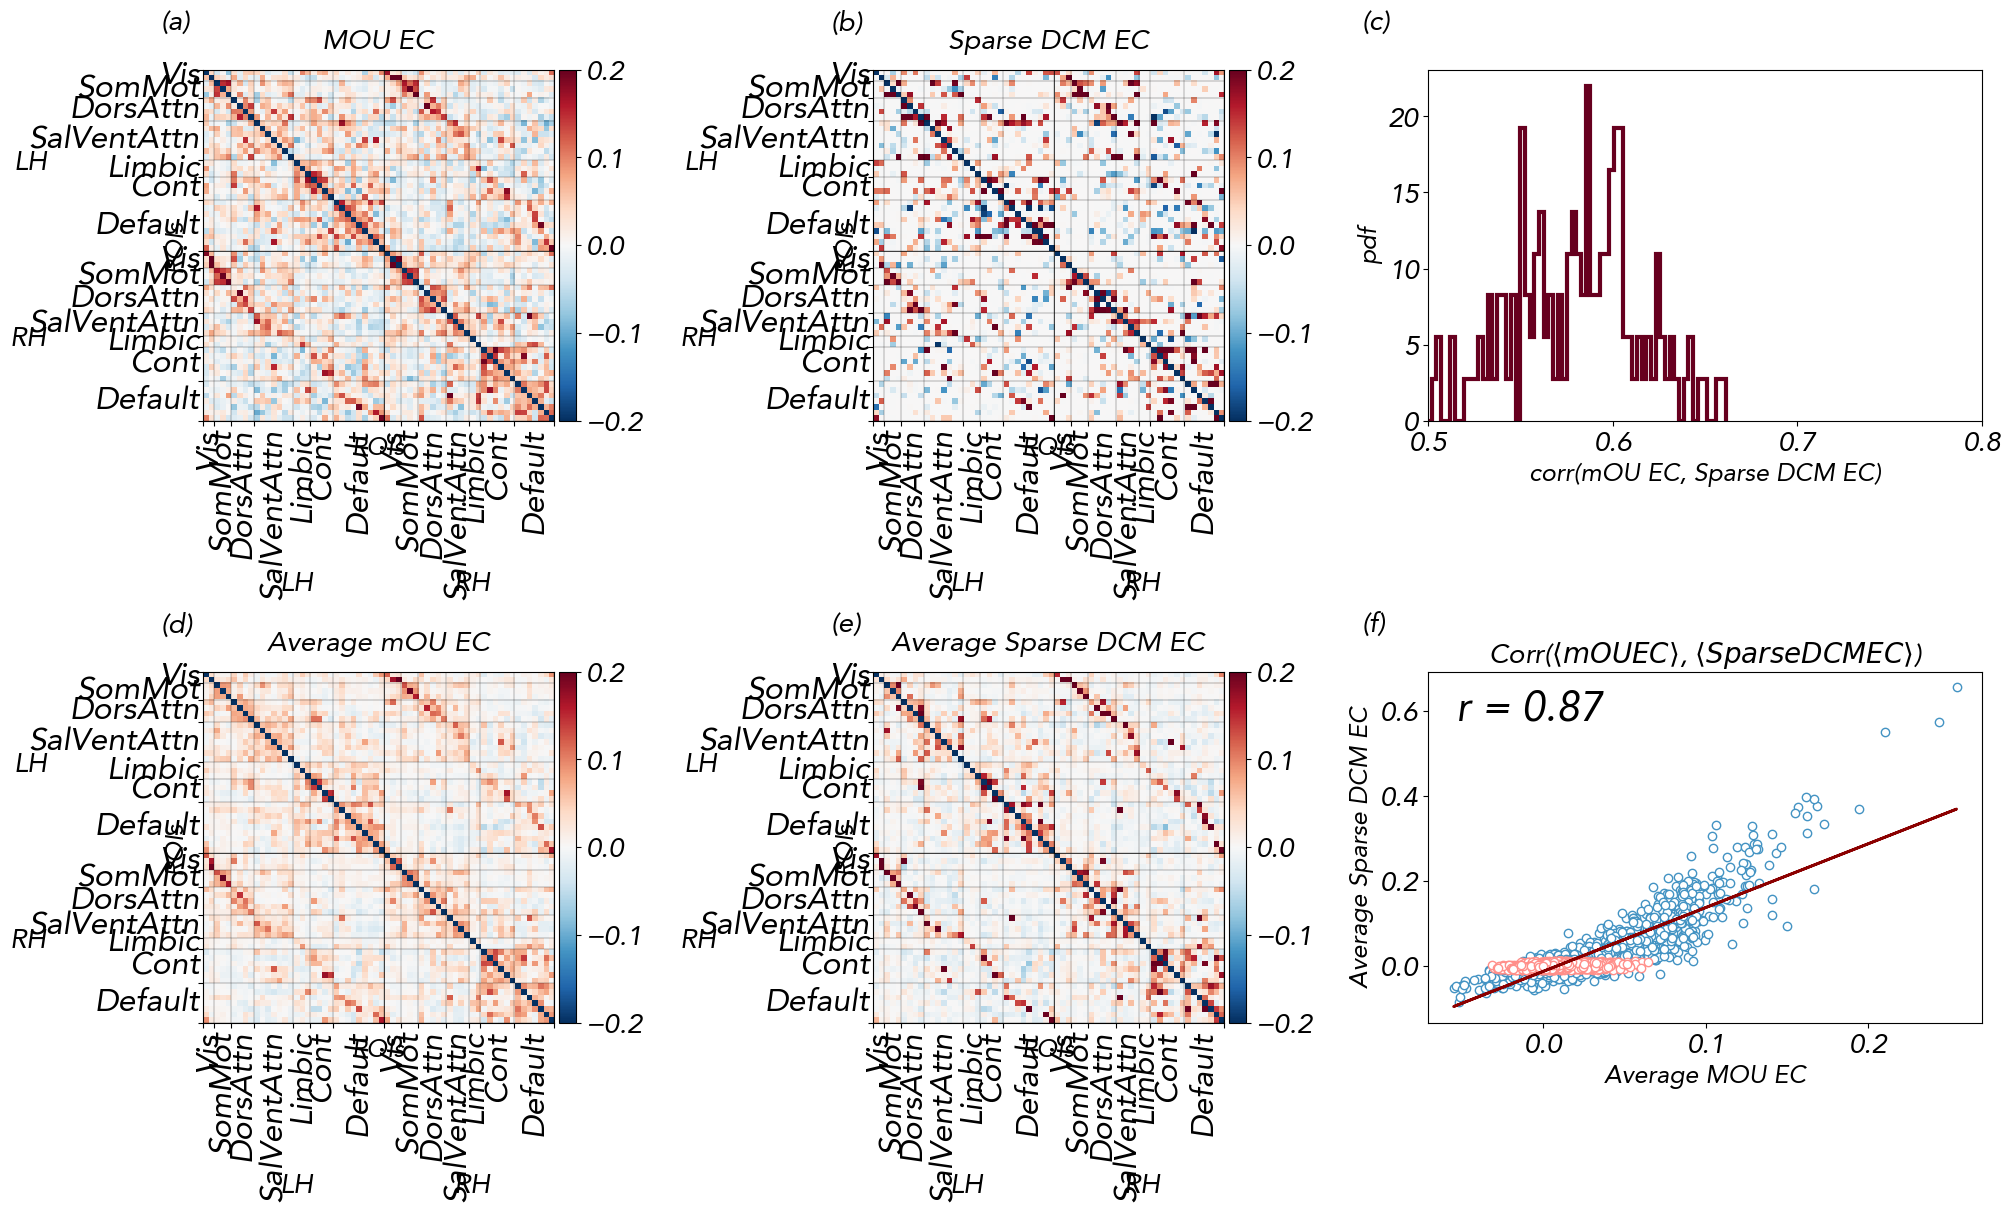

In [44]:

fig, axes = plt.subplots(2, 3, figsize=(20,12) , constrained_layout=True)
from mpl_toolkits.axes_grid1 import make_axes_locatable
#subject = 44
maschera = np.zeros(1013)
indici =np.asarray(indici)
maschera[indici] = 1
maschera = maschera.astype(bool)
maschera[100]

from matplotlib import cm
colors = cm.RdBu_r(np.linspace(0,1,10))
#12


# Primo pannello
v = [0.2,0.2]
#mat = loadmat(pat + np.sort(os.listdir('/readonly/insights/RESULTS_YA_new_1000/RESULTS_YA_new_1000_RUN1_noisevar/'))[subject])['A']
js=[JS[indicia,:62,:62][2],JS_dcm[2,:62,:62].T]

#js =[JS[subject][:62,:62], JS_100_1[subject][:100,:100], JS_200_1[subject][:200,:200], JS[subject][:62,:62],cluster_regions_EC(JS_100_1[subject][:100,:100], aggregate[:100]), cluster_regions_EC(mapping_100_200(JS_200_1[subject][:200,:200]), aggregate[:100])]

titles = ['MOU EC', 'Sparse DCM EC',]
for i,ax in enumerate(axes.reshape(-1)[:2]):
    im= plot_fc_matrix(
    js[i],
    new_lab,
    ax,
    cmap="RdBu_r",
    vmin=-v[i],
    vmax=v[i]
)
    divider = make_axes_locatable(ax)
    cax = divider.append_axes('right', size='5%', pad=0.05)
    fig.colorbar(im, cax=cax, orientation='vertical')
    ax.set_title(f"{titles[i]}",pad=15)
    ax.set_xlabel('ROIs')
    ax.set_ylabel('ROIs')
    
    

c=[]
for i in range(JS_dcm[:].shape[0]):
    mask = np.abs(JS_dcm[i,:62,:62])< 1e-2
    mask = np.logical_not(mask)
    corr=np.corrcoef(dediag(JS_dcm[i,:62,:62])[mask],dediag(JS[indicia][i,:62,:62].T)[mask])[0,1]
    c.append(corr)


axes[0,2].hist(c, bins = 70, color ='white', edgecolor =colors[-1],lw = 3, histtype = 'step', density =True);
axes[0,2].set_xlabel('corr(mOU EC, Sparse DCM EC)')
axes[0,2].set_ylabel('pdf')
axes[0,2].set_xlim(0.5,0.8)


#print(slope, r)
from scipy import stats
#res = stats.spearmanr(x.flatten(), y.flatten())
# Titolo completo
#print('sp', res)
#axes[0,2].set_title(f"{titles[i]}")
#axes[0,2].set_ylabel('Sparse DCM EC')
#axes[0,2].set_xlabel('MOU EC') if i == 0 else axes[0,2].set_xlabel('MOU EC') 

# Primo pannello
v = [0.2,0.2]
#mat = loadmat(pat + np.sort(os.listdir('/readonly/insights/RESULTS_YA_new_1000/RESULTS_YA_new_1000_RUN1_noisevar/'))[subject])['A']
js=[np.mean(JS[indicia,:62,:62][:73],0),np.mean(JS_dcm[:73,:62,:62],0)]

#js =[JS[subject][:62,:62], JS_100_1[subject][:100,:100], JS_200_1[subject][:200,:200], JS[subject][:62,:62],cluster_regions_EC(JS_100_1[subject][:100,:100], aggregate[:100]), cluster_regions_EC(mapping_100_200(JS_200_1[subject][:200,:200]), aggregate[:100])]

titles = ['Average mOU EC', 'Average Sparse DCM EC',]
for i,ax in enumerate(axes.reshape(-1)[3:5]):
    im=plot_fc_matrix(
        js[i],
        new_lab,
        ax,
        cmap="RdBu_r",
        vmin=-v[i],
        vmax=v[i]
    )
    divider = make_axes_locatable(ax)
    cax = divider.append_axes('right', size='5%', pad=0.05)
    fig.colorbar(im, cax=cax, orientation='vertical')
    ax.set_title(f"{titles[i]}",pad=15)
    ax.set_xlabel('ROIs')
    ax.set_ylabel('ROIs')
    


x = (dediag(js[0]))

y = (dediag(js[1]))
mask = np.abs(y)<1e-2


x = (dediag(js[0]))[np.logical_not(mask)]
y = (dediag(js[1]))[np.logical_not(mask)]

res = linregress(x.flatten(), y.flatten())
slope, intercept, r, p = res.slope, res.intercept, round(res.rvalue,2), res.pvalue


im= axes[1,2].scatter(x,y,c = 'white',edgecolor ="#4393c3") #(blu molto scuro))
#, vmin=-v[i], vmax=v[i], cmap = 'bwr');


y_line = slope * x.flatten() + intercept
axes[1,2].plot(x.flatten(), y_line, linewidth=2, color ='darkred')

x = dediag(js[0])[(mask)]
y = (dediag(js[1]))[(mask)]



im= axes[1,2].scatter(x,y,c = 'white',edgecolor = "#ff8f8a"
              )

print(slope, r)
from scipy import stats
#res = stats.spearmanr(x.flatten(), y.flatten())
# Titolo completo
#print('sp', res)
axes[1,2].set_title(r"Corr($\langle mOU EC \rangle$, $\langle Sparse DCM EC \rangle$)")
axes[1,2].set_ylabel('Average Sparse DCM EC')
axes[1,2].set_xlabel('Avergage MOU EC') if i == 0 else axes[1,2].set_xlabel('Average MOU EC') 





# --- Testo dentro la figura ---
text_str = f"r = {r:.2f}"
axes[1,2].text(
    0.05, 0.95,              # posizione (fractions dell'asse)
    text_str,
    transform=axes[1,2].transAxes,  # usa coordinate normalizzate
    verticalalignment='top',
    fontsize=30,
    bbox=dict(facecolor='white', alpha=0.7, edgecolor='none')
    )
#plt.tight_layout()
import string
labels = list(string.ascii_lowercase)  # a, b, c, d, ...

for ax, lab in zip(axes.flatten(), labels):
    ax.text(
        -0.12, 1.17,                 # posizione (fuori dall'asse)
        f"({lab})",
        transform=ax.transAxes,
        fontsize=20,
        fontweight='bold',
        va='top',
        ha='left'
    )
plt.subplots_adjust(hspace=.4, wspace=.6)
#plt.savefig('../../Figures/comparison_w_hcp.jpg', dpi = 300, bbox_inches ='tight');

In [10]:
ikk=[]
pat = '/readonly/insights/RESULTS_YA_new_1000/RESULTS_YA_new_1000_RUN1_noisevar/'
for i in os.listdir('/readonly/insights/RESULTS_YA_new_1000/RESULTS_YA_new_1000_RUN1_noisevar/'):
    if i[-10:-4] in sub_tot:
        ikk.append(i[-10:-4])
sub_tot = np.asarray(sub_tot)        
ikk = np.sort(ikk)
indicia = np.asarray([np.where(ikk[i]==sub_tot)[0] for i in range(len(ikk))]).reshape(-1)
len(indicia)


ikk2=[]
pat = '/readonly/insights/RESULTS_YA_new_1000/RESULTS_YA_new_1000_RUN2/'
for i in os.listdir('/readonly/insights/RESULTS_YA_new_1000/RESULTS_YA_new_1000_RUN2/'):
    if i[-10:-4] in sub_tot:
        ikk2.append(i[-10:-4])
sub_tot = np.asarray(sub_tot)        
ikk2 = np.sort(ikk2)
indicia2 = np.asarray([np.where(ikk2[i]==sub_tot)[0] for i in range(len(ikk2))]).reshape(-1)
len(indicia2)


indici= np.sort(list(set(indicia) & set(indicia2)))
#len(subdcm)

In [11]:
sub_dcm =sub_tot[indici]
len(sub_dcm)
sub_tot

array(['100206', '100307', '100408', ..., '993675', '994273', '996782'],
      dtype='<U6')

In [ ]:
import os
import numpy as np
from scipy import signal
from tqdm import tqdm
MAX_ITER = 100
c = []
JS =[]
ec_dcm=[]
tau_est = np.load('../numpy files/est_tau_delta.npy')
filtered_taus = tau_est[indici]
# ==========================================================
# Main loop
# ==========================================================

for l, sub_ in enumerate(tqdm(sub_dcm[:])):

    file_path = (
        f'/home/benedetta/hcp_parcellated/{sub_}/'
        f'{sub_}_REST1_LR_Schaefer100+AAL.npy'
    )

    if not os.path.exists(file_path):
        continue

    data_1 = np.load(file_path)

    b, a = signal.butter(
        2,
        [0.01, 0.1],
        btype='bandpass',
        fs=1 / 0.72
    )

    data_ref = signal.filtfilt(
        b,
        a,
        data_1,
        axis=0
    )

    Y = cluster_regions(data_ref[:, :100], aggregate[:100])


    # Empirical covariance and lagged covariance
    Q0 = calc_Corr0(Y)
    Q1 = calc_Corrlag(Y, 1)

    tau_ = filtered_taus[l]

    m = MOU()

    m.fit_LO(
        Q0,
        Q1,
        lag=1,
        prior=0.0,
        tau=float(tau_),
        eta_C=0.005,
        max_iter=MAX_ITER, regul_C = 0,
    )

    J_prior = m.J.copy()
    JS.append(J_prior)
    a = loadmat(f'../../../codici/results/sub-{sub_}.mat_TR1_realData_var11_emo_points16.mat')['A']
    ec_dcm.append(a)

    mask = np.abs(a)< 1e-2
    mask = np.logical_not(mask)
    corr=np.corrcoef(dediag(a)[mask],dediag(J_prior.T)[mask])[0,1]
    #indici.append(index)
    #index
    c.append(corr)
            

In [43]:
#ls '../numpy files/'
#plt.plot(sub_dcm)

In [10]:
import os
import numpy as np
from scipy import signal
from tqdm import tqdm
MAX_ITER = 100
c = []
JS =[]
ec_dcm=[]
tau_est = np.load('../numpy files/est_tau_delta.npy')
filtered_taus = tau_est[indici]
# ==========================================================
# Main loop
# ==========================================================

for l, sub_ in enumerate(tqdm(sub_dcm[:])):

    file_path = (
        f'/home/benedetta/hcp_parcellated/{sub_}/'
        f'{sub_}_REST1_LR_Schaefer100+AAL.npy'
    )

    if not os.path.exists(file_path):
        continue

    data_1 = np.load(file_path)

    b, a = signal.butter(
        2,
        [0.01, 0.1],
        btype='bandpass',
        fs=1 / 0.72
    )

    data_ref = signal.filtfilt(
        b,
        a,
        data_1,
        axis=0
    )

    Y = cluster_regions(data_ref[:, :100], aggregate[:100])


    # Empirical covariance and lagged covariance
    Q0 = calc_Corr0(Y)
    Q1 = calc_Corrlag(Y, 1)

    tau_ = filtered_taus[l]

    m = MOU()

    m.fit_LO(
        Q0,
        Q1,
        lag=1,
        prior=0.0,
        tau=float(tau_),
        eta_C=0.005,
        max_iter=MAX_ITER, regul_C = 0,
    )

    J_prior = m.J.copy()
    JS.append(J_prior)
    a = loadmat(f'../../../codici/results/sub-{sub_}.mat_TR1_realData_var11_emo_points16.mat')['A']
    ec_dcm.append(a)

    mask = np.abs(a)< 1e-2
    mask = np.logical_not(mask)
    corr=np.corrcoef(dediag(a)[mask],dediag(J_prior.T)[mask])[0,1]
    #indici.append(index)
    #index
    c.append(corr)
            

NameError: name 'sub_dcm' is not defined

In [31]:
ls '../numpy files/regul_C'

corr__100.npy  corr_100.npy  my_info_ec_100.npy


In [23]:
#len(os.listdir('../../codici/results'))

o=0
c = []
ec_dcm =[]
indici=[]
JS = np.load('../numpy files/EC_matrix_HCP1_74.npy')

for i in os.listdir('../../../codici/results'):
    if 'TR1_realData_var11_emo_points16.' in i:
        #print(i[:10])
        sub_ = i[4:10]
        
        a = loadmat(f'../../../codici/results/sub-{sub_}.mat_TR1_realData_var11_emo_points16.mat')['A']
        if a.shape[0] ==62:
            #print(i)
            ec_dcm.append(a)
            sub_tot= np.asarray(sub_tot)
            index = np.where(sub_tot == sub_)[0][0]
            mask = np.abs(a)< 1e-2
            mask = np.logical_not(mask)
            corr=np.corrcoef(dediag(a)[mask],dediag(JS[index,:62,:62].T)[mask])[0,1]
            indici.append(index)
            #index
            c.append(corr)
            #print(np.corrcoef(dediag(JS[index][:62,:62]).flatten(), dediag(a).T.flatten())[0,1])
            o+=1
o

144

In [13]:
def plot_fc_matrix(fc, labels, ax, cmap="bwr", vmin=-0.2, vmax=0.2, fontsize = 13, pos = 7, plot_emi_x =True,plot_emi_y =True):

    def parse_label(lab):
        return lab.split("_")[0], lab.split("_")[1]

    # ---- grouping ----
    groups = OrderedDict()
    for i, lab in enumerate(labels):
        hemi, net = parse_label(lab)
        groups.setdefault(f"{hemi}_{net}", []).append(i)

    new_order, bounds, names = [], [], []
    start = 0

    for key, idxs in groups.items():
        new_order.extend(idxs)
        end = start + len(idxs)
        bounds.append((start, end))
        names.append(key)
        start = end

    fc_ord = fc[np.ix_(new_order, new_order)]
    n = fc_ord.shape[0]

    im = ax.imshow(fc_ord, cmap=cmap, vmin=vmin, vmax=vmax)

    # ---- boundaries ----
    ticks = [0] + [end for _, end in bounds]

    ax.set_xticks(np.array(ticks)-.5)
    ax.set_yticks(np.array(ticks)-.5)
    ax.set_xticklabels([])
    ax.set_yticklabels([])

    ax.tick_params(axis='x', bottom=True, labelbottom=True)

    for t in ticks:
        ax.axhline(t - 0.5, color="black", linewidth=0.2)
        ax.axvline(t - 0.5, color="black", linewidth=0.2)

    # ---- LH / RH separation ----
    lh_count = sum(lab.startswith("LH_") for lab in labels)
    ax.axhline(lh_count - 0.5, color="black", linewidth=0.5)
    ax.axvline(lh_count - 0.5, color="black", linewidth=0.5)

        # ---- labels ----
    for (start, end), name in zip(bounds, names):
        center = (start + end) / 2
        hemi, net = name.split("_")
    
        ax.text(center-.5, n + 1, f"{net}",
                ha="center", va="top",
                rotation=70, clip_on=False,fontsize = fontsize)
    
        ax.text(-1, center-.5, f"{net}",
                ha="right", va="center", clip_on=False,fontsize = fontsize )
    
        ax.set_xlim(-0.5, n - 0.5)
        ax.set_ylim(n - 0.5, -0.5)
        
    # ---- LH / RH labels ----
    lh_center = lh_count / 2
    rh_center = lh_count + (n - lh_count) / 2
    
    offset_x = n + 1   # distanza sull'asse x (sopra le label dei network)
    offset_y = -1    # distanza sull'asse y (a sinistra delle label dei network)
    
    # Asse X (sopra)
    if plot_emi_x:
        ax.text(lh_center 
                , offset_x+pos, "LH",
                ha="center", va="top",
                fontweight='bold', clip_on=False, fontsize = 20)
        ax.text(rh_center , offset_x+pos, "RH",
                ha="center", va="top",
                fontweight='bold', clip_on=False, fontsize = 20)
    if plot_emi_y:
        # Asse Y (sinistra)
        ax.text(offset_y-pos, lh_center , "LH",
                ha="right", va="center",
                fontweight='bold', clip_on=False, fontsize = 20)
        ax.text(offset_y-pos, rh_center , "RH",
                ha="right", va="center",
                fontweight='bold', clip_on=False, fontsize = 20)

    return im

In [22]:
taus = np.round(np.logspace(-0.4, 2),2)
taus.shape, #np.load('numpy files/ass_74_102sub.npy').shape

((50,),)

In [17]:
np.mean(corrs), np.percentile(corrs,5),np.percentile(corrs,95)

(np.float64(0.8163077872864857),
 np.float64(0.7689305101456829),
 np.float64(0.856658748407833))

In [35]:
ec_dcm=np.asarray(ec_dcm)
JS = np.asarray(JS)
JS.shape, len(c)

((144, 62, 62), 144)

0.9813789416610385


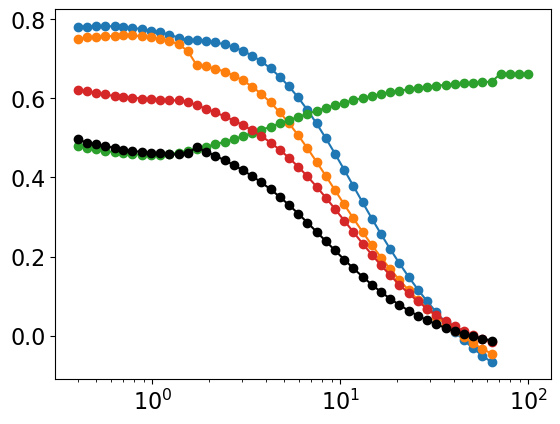

In [72]:
_1 = np.load('../numpy files/corr__62_1013_log.npy')
_2 = np.load('../numpy files/corr_62_1013_log.npy')
_3 = np.load('../numpy files/my_info_ec_1013_62.npy')
__1 = np.load('../numpy files/corr__100_1013_log.npy')
__2 = np.load('../numpy files/corr_100_1013_log.npy')
#__3 = np.load('../numpy files/my_info_ec_1013_62.npy')
n = 82
plt.plot(taus,_1[indici][n],'o-')
plt.plot(taus,__1[indici][n],'o-')
plt.plot(taus,_3[indici][n],'-o')

plt.plot(taus,-_2[indici][n],'-o')
plt.plot(taus,__2[indici][n],'-o', color='black'),

print(tau_est[indici][n])
plt.xscale('log');

0.9813789416610385


(0.0, 10.0)

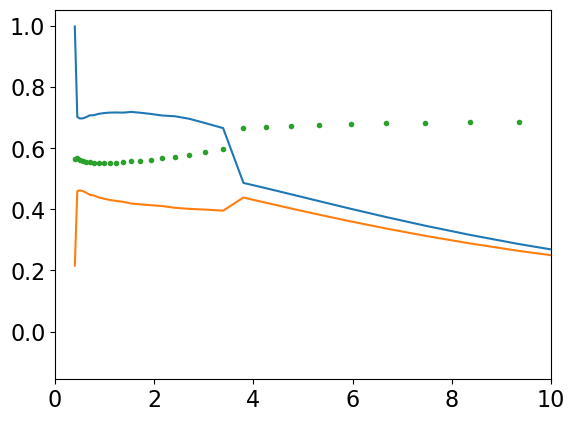

In [50]:
_1 = np.load('../numpy files/corr__62_1013_log.npy')
_2 = np.load('../numpy files/corr_62_1013_log.npy')
_3 = np.load('../numpy files/my_info_ec_1013_62.npy')
plt.plot(taus,_1[indici][108])
plt.plot(taus,-_2[indici][108])
plt.plot(taus,_3[indici][108],

print(tau_est[indici][108])
#plt.xscale('log')
plt.xlim(0,10)

108
108
BEST: 82 0.88
WORST: 108 0.69


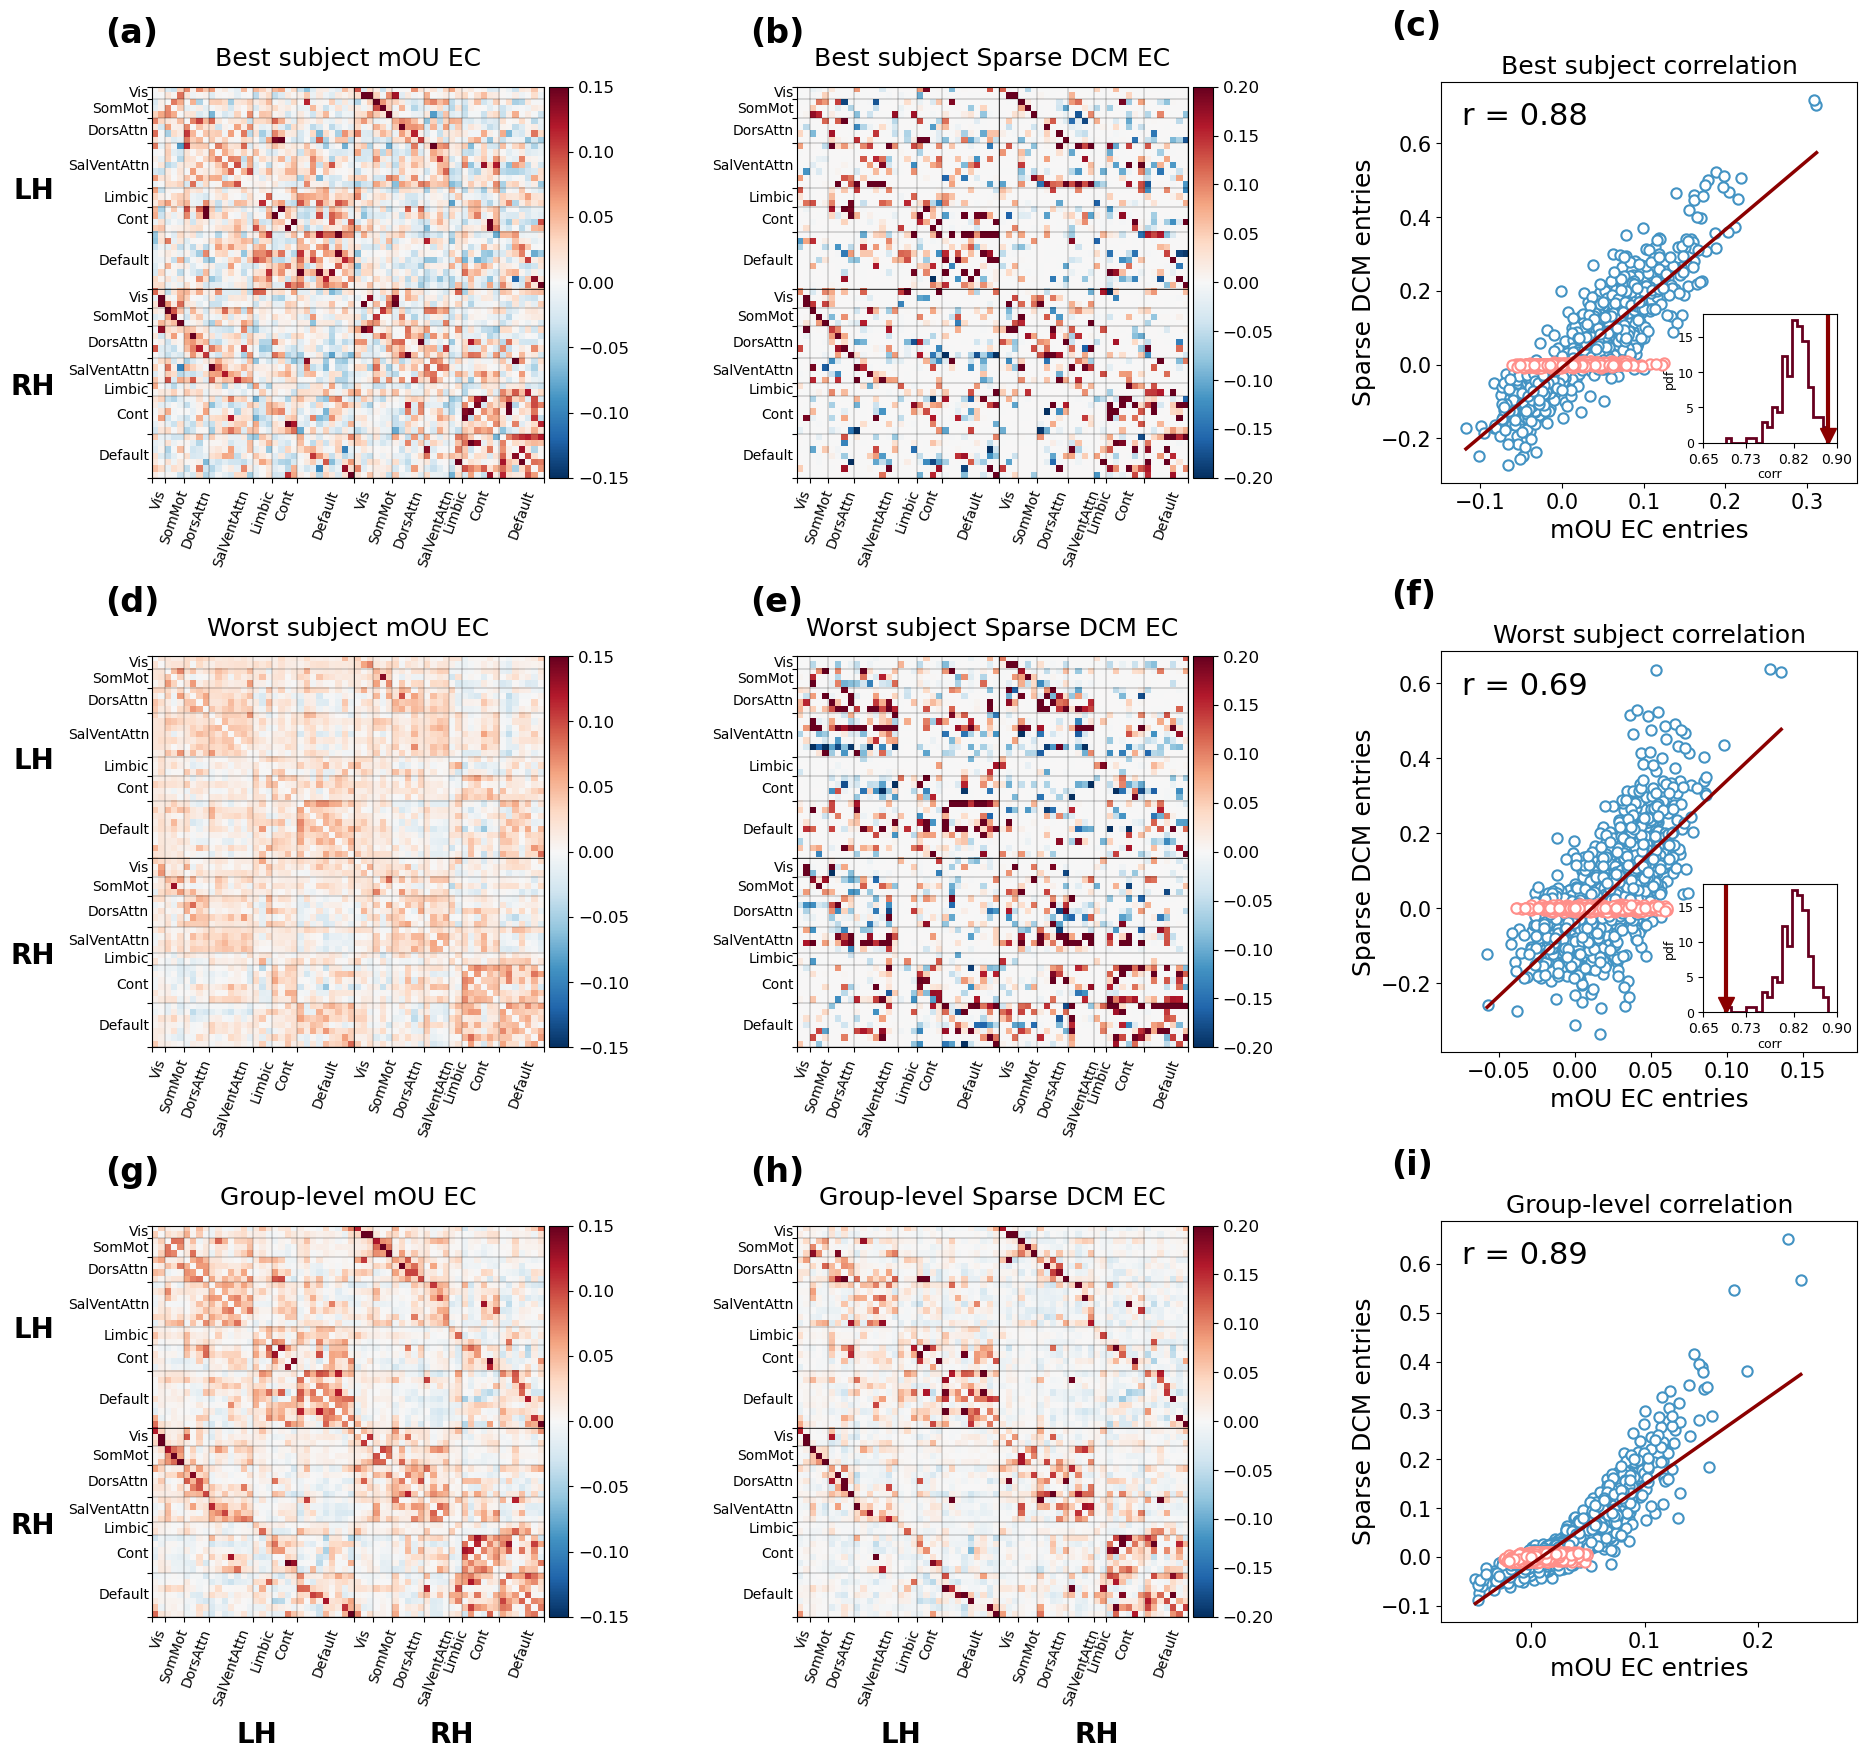

In [36]:
plt.rcParams['font.size'] = 8

from collections import OrderedDict
from scipy.stats import linregress
from matplotlib import cm
from mpl_toolkits.axes_grid1 import make_axes_locatable
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import string

# =========================================================
# STYLE
# =========================================================

colors = cm.RdBu_r(np.linspace(0,1,10))

plt.rcParams["axes.titlesize"] = 18
plt.rcParams["axes.labelsize"] = 18
plt.rcParams["xtick.labelsize"] = 16
plt.rcParams["ytick.labelsize"] = 16

# =========================================================
# LOAD DATA
# =========================================================

#JS = np.load('numpy files/EC_matrix_HCP1_74.npy')

# =========================================================
# COMPUTE SUBJECT CORRELATIONS
# =========================================================

corrs = []

for i in range(ec_dcm.shape[0]):

    x = dediag(JS[i,:62,:62])
    y = dediag(ec_dcm[i,:62,:62].T)

    mask = np.abs(y) < 1e-2
    mask = np.logical_not(mask)

    r = np.corrcoef(
        x[mask].flatten(),
        y[mask].flatten()
    )[0,1]

    corrs.append(r)

corrs = np.asarray(corrs)
indeces = np.argsort(corrs)
best_idx = np.nanargmax(corrs)
worst_idx = np.nanargmin(corrs)
print(worst_idx)
worst_idx = indeces[0]
print(worst_idx)

print('BEST:', best_idx, round(corrs[best_idx],2))
print('WORST:', worst_idx, round(corrs[worst_idx],2))

# =========================================================
# HIST RANGE
# =========================================================

xmin = 0.65
xmax = np.ceil(np.max(corrs)*10)/10

# =========================================================
# FIGURE
# =========================================================

fig, axes = plt.subplots(
    3,
    3,
    figsize=(22,20)
)

v = [0.15, 0.2]
pos = 15

# =========================================================
# HELPER FUNCTION
# =========================================================

def plot_row(row_axes, js, title_prefix, plot_emi_x, group_level= False):

    titles = [
        f'{title_prefix} mOU EC',
        f'{title_prefix} Sparse DCM EC'
    ]

    # =====================================================
    # MATRICES
    # =====================================================

    for i, ax in enumerate(row_axes[:2]):
        if i ==0:
        
            
            plot_emi_y=True
        else:
             plot_emi_y=False
        im = plot_fc_matrix(
            js[i],
            new_lab,
            ax,
            cmap="RdBu_r",
            vmin=-v[i],
            vmax=v[i],
            fontsize=10,
            pos=pos,plot_emi_x=plot_emi_x, plot_emi_y=plot_emi_y
        )

        divider = make_axes_locatable(ax)

        cax = divider.append_axes(
            'right',
            size='5%',
            pad=0.05
        )

        cb = fig.colorbar(im, cax=cax)

        cb.ax.tick_params(
            labelsize=12
        )

        ax.set_title(
            titles[i],
            pad=15,
            fontsize=18
        )

    # =====================================================
    # SCATTER
    # =====================================================

    ax = row_axes[2]

    x = dediag(js[0])
    y = dediag(js[1])

    mask = np.abs(y) < 1e-2

    xnz = x[~mask]
    ynz = y[~mask]

    res = linregress(
        xnz.flatten(),
        ynz.flatten()
    )

    slope = res.slope
    intercept = res.intercept
    r = res.rvalue

    # -----------------------------------------------------
    # NONZERO ENTRIES
    # -----------------------------------------------------

    ax.scatter(
        xnz,
        ynz,
        c='white',
        edgecolor="#4393c3",
        s=55,
        linewidth=1.5
    )

    # -----------------------------------------------------
    # ZERO ENTRIES
    # -----------------------------------------------------

    ax.scatter(
        x[mask],
        y[mask],
        c='white',
        edgecolor="#ff8f8a",
        s=55,
        linewidth=1.5
    )

    # -----------------------------------------------------
    # REGRESSION LINE
    # -----------------------------------------------------

    xx = np.linspace(
        np.min(xnz),
        np.max(xnz),
        200
    )

    yy = slope * xx + intercept

    ax.plot(
        xx,
        yy,
        linewidth=2.5,
        color='darkred'
    )

    # -----------------------------------------------------
    # LABELS
    # -----------------------------------------------------
    ax.set_xlim(np.min(xnz)-0.03, np.max(xnz) +0.05)
    ax.set_xlabel(
        'mOU EC entries',
        fontsize=18
    )

    ax.set_ylabel(
        'Sparse DCM entries',
        fontsize=18
    )

    ax.set_title(
        f'{title_prefix} correlation',
        fontsize=18
    )

    ax.tick_params(
        axis='both',
        labelsize=15
    )

    # -----------------------------------------------------
    # CORRELATION TEXT
    # -----------------------------------------------------

    ax.text(
        0.05,
        0.95,
        f"r = {r:.2f}",
        transform=ax.transAxes,
        verticalalignment='top',
        fontsize=22,
        bbox=dict(
            facecolor='white',
            alpha=0.8,
            edgecolor='none'
        )
    )

    # =====================================================
    # INSET HISTOGRAM
    # =====================================================
    if not group_level:
        axins = inset_axes(
            ax,
            width="32%",
            height="32%",
            loc='lower left',
            bbox_to_anchor=(0.63, 0.1, 1, 1),  # <-- posizione controllata
            bbox_transform=ax.transAxes,
            borderpad=0
        )
    
        axins.hist(
            corrs,
            bins=20,
            density=True,
            color='white',
            edgecolor=colors[-1],
            lw=2,
            histtype='step'
        )
    
        axins.axvline(
            r,
            color='darkred',
            lw=3
        )
    
        axins.plot(
            r,
            1,
            marker='v',
            color='darkred',
            ms=12
        )
    
        # -----------------------------------------------------
        # HIST FORMATTING
        # -----------------------------------------------------
    
        axins.set_xlim(
            xmin,
            xmax
        )
    
        axins.set_xticks(
            np.round(
                np.linspace(xmin, xmax, 4),
                2
            )
        )
    
        axins.tick_params(
            axis='x',
            labelsize=10
        )
    
        axins.tick_params(
            axis='y',
            labelsize=9
        )
    
        axins.set_xlabel(
            'corr',
            fontsize=9,
            labelpad=1
        )
    
        axins.set_ylabel(
            'pdf',
            fontsize=9,
            labelpad=1
        )
    
        #axins.set_title(
         #   'distribution',
          #  fontsize=9,
          #  pad=2
        #)

    return r

# =========================================================
# BEST SUBJECT
# =========================================================

js_best = [
    dediag(JS[best_idx,:62,:62]),
    dediag(ec_dcm[best_idx,:62,:62].T)
]

plot_row(
    axes[0],
    js_best,
    'Best subject', False
)

# =========================================================
# WORST SUBJECT
# =========================================================

js_worst = [
    dediag(JS[worst_idx,:62,:62]),
    dediag(ec_dcm[worst_idx,:62,:62].T)
]

plot_row(
    axes[1],
    js_worst,
    'Worst subject', False
)

# =========================================================
# GROUP LEVEL
# =========================================================

js_group = [
    dediag(np.mean(JS[:,:62,:62],0)),
    dediag(np.mean(ec_dcm[:,:62,:62],0).T)
]

plot_row(
    axes[2],
    js_group,
    'Group-level', True, True
)

# =========================================================
# PANEL LABELS
# =========================================================

labels_panels = list(string.ascii_lowercase)

for ax, lab in zip(axes.flatten(), labels_panels):

    ax.text(
        -0.12,
        1.18,
        f"({lab})",
        transform=ax.transAxes,
        fontsize=24,
        fontweight='bold',
        va='top',
        ha='left'
    )

# =========================================================
# LAYOUT
# =========================================================

plt.subplots_adjust(
    hspace=.42,
    wspace=.55
)
#plt.savefig(
 #    'Figures/comparison_revised.jpg',
 #    dpi=300,
 #    bbox_inches='tight'
 #)
plt.show()

In [56]:
filtered_taus[82],np.mean(tau_est)

(np.float64(0.9813789416610385), np.float64(0.8121752353620063))

60
60
BEST: 11 0.88
WORST: 60 0.69


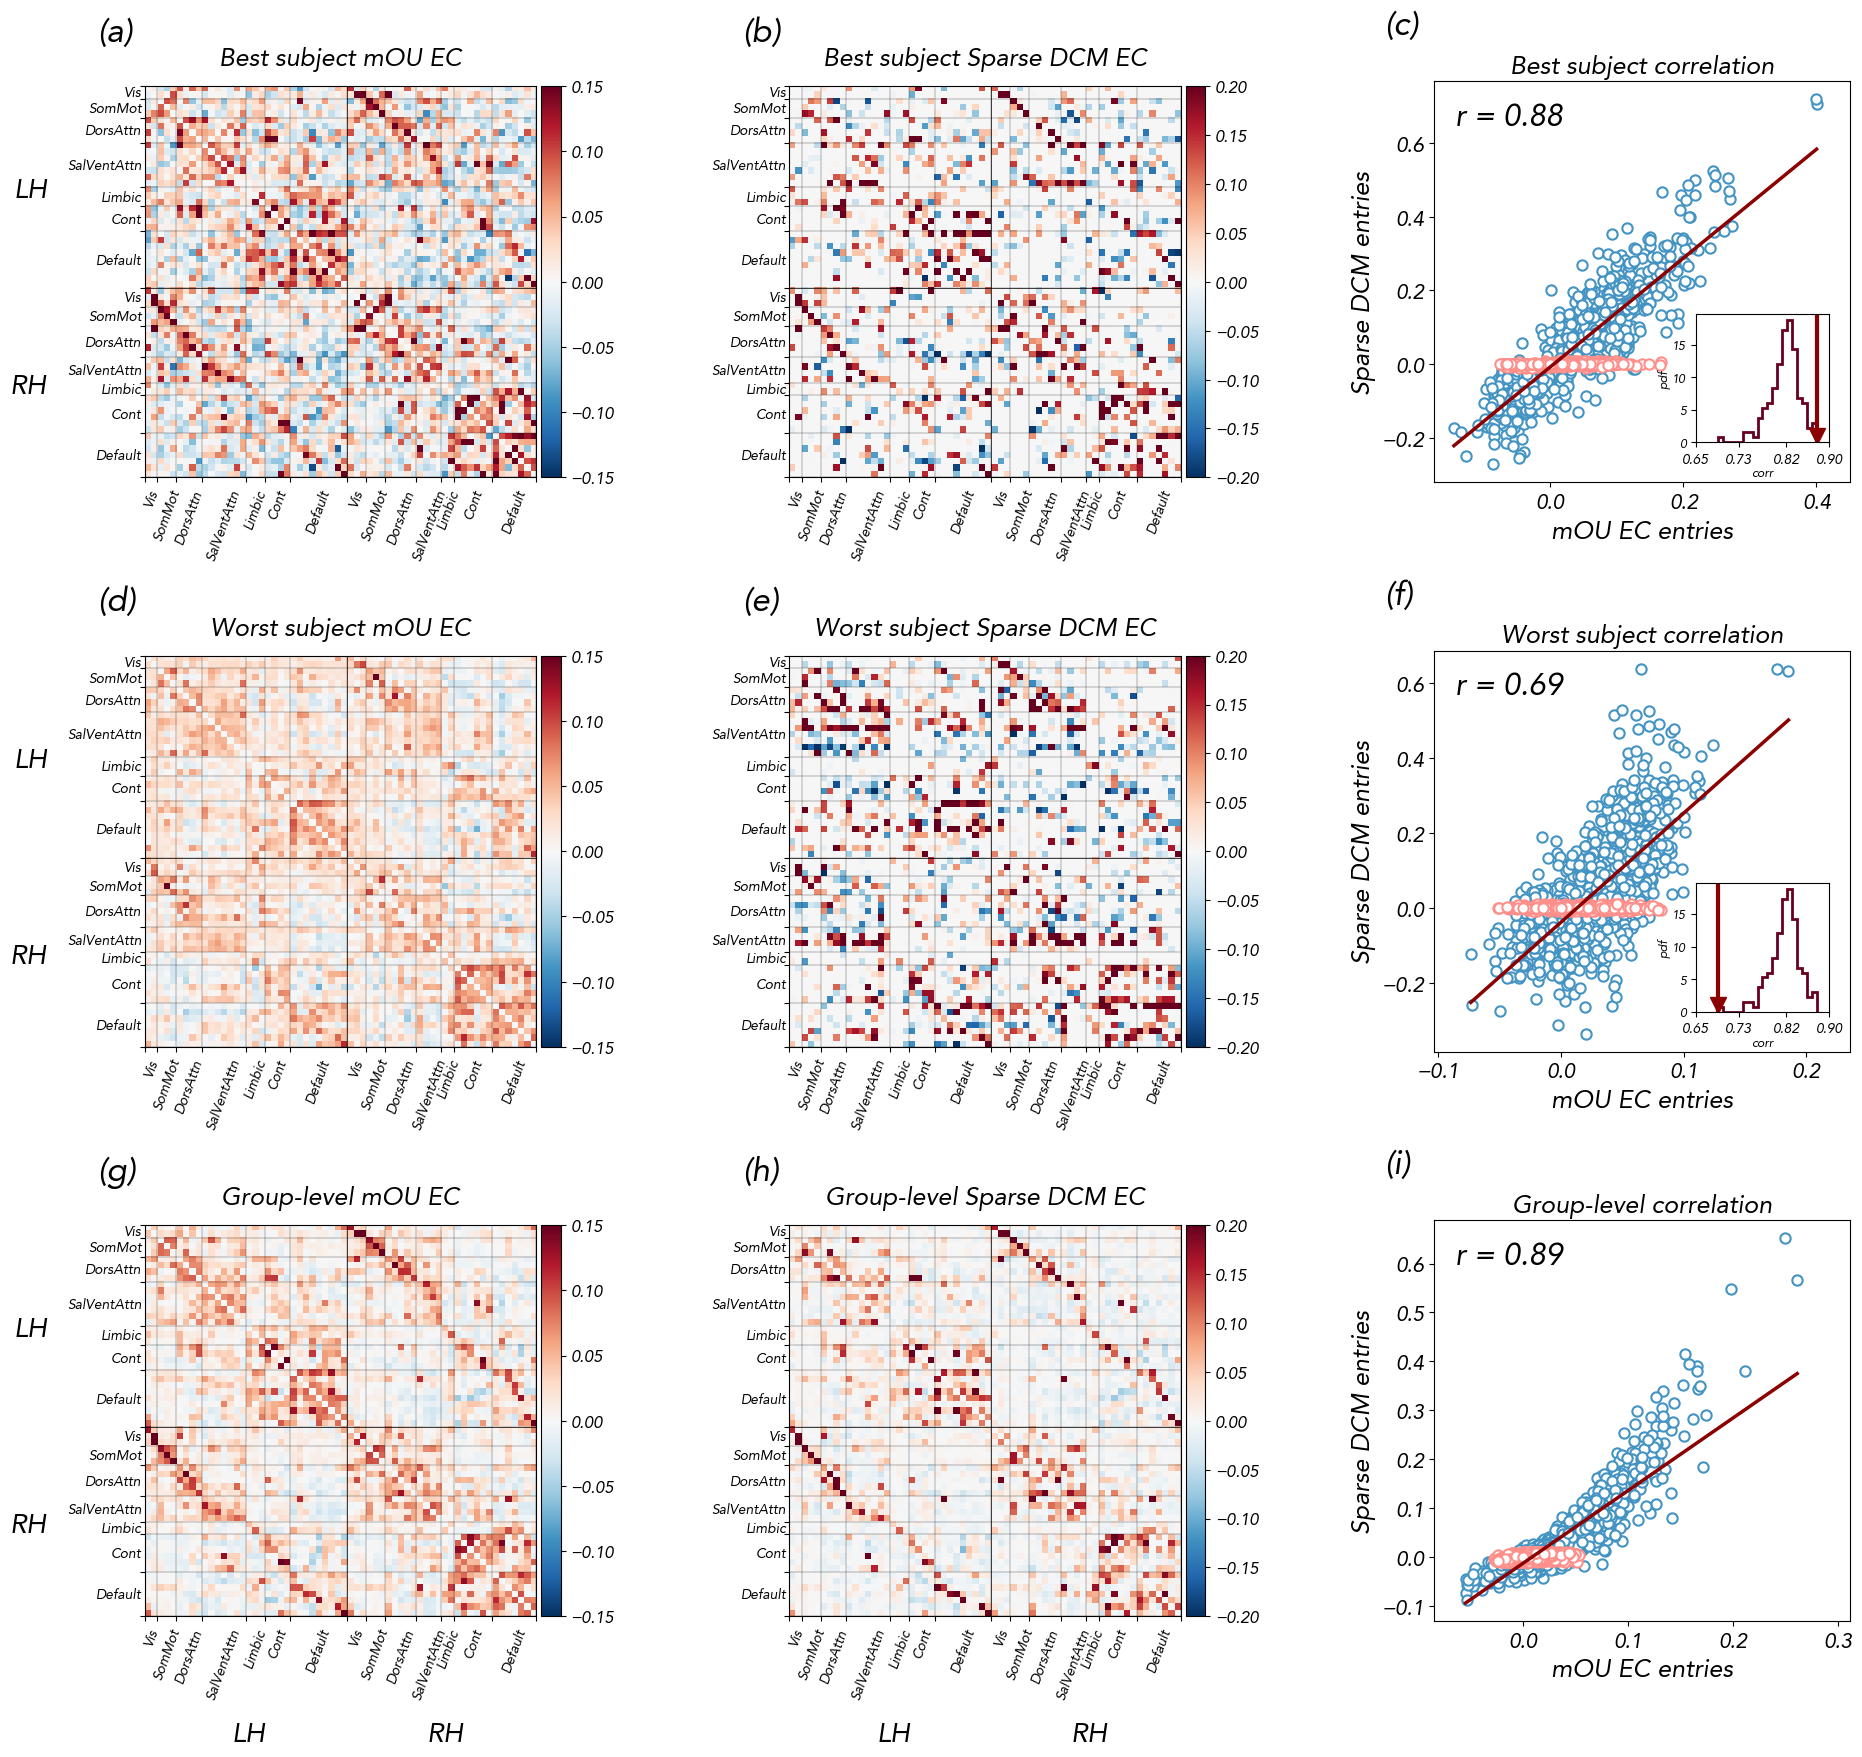

In [47]:
plt.rcParams['font.size'] = 8

from collections import OrderedDict
from scipy.stats import linregress
from matplotlib import cm
from mpl_toolkits.axes_grid1 import make_axes_locatable
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import string

# =========================================================
# STYLE
# =========================================================

colors = cm.RdBu_r(np.linspace(0,1,10))

plt.rcParams["axes.titlesize"] = 18
plt.rcParams["axes.labelsize"] = 18
plt.rcParams["xtick.labelsize"] = 16
plt.rcParams["ytick.labelsize"] = 16

# =========================================================
# LOAD DATA
# =========================================================

JS = np.load('numpy files/EC_matrix_HCP1_74.npy')

# =========================================================
# COMPUTE SUBJECT CORRELATIONS
# =========================================================

corrs = []

for i in range(ec_dcm.shape[0]):

    x = dediag(JS[indici][i,:62,:62])
    y = dediag(ec_dcm[i,:62,:62].T)

    mask = np.abs(y) < 1e-2
    mask = np.logical_not(mask)

    r = np.corrcoef(
        x[mask].flatten(),
        y[mask].flatten()
    )[0,1]

    corrs.append(r)

corrs = np.asarray(corrs)
indeces = np.argsort(corrs)
best_idx = np.nanargmax(corrs)
worst_idx = np.nanargmin(corrs)
print(worst_idx)
worst_idx = indeces[0]
print(worst_idx)

print('BEST:', best_idx, round(corrs[best_idx],2))
print('WORST:', worst_idx, round(corrs[worst_idx],2))

# =========================================================
# HIST RANGE
# =========================================================

xmin = 0.65
xmax = np.ceil(np.max(corrs)*10)/10

# =========================================================
# FIGURE
# =========================================================

fig, axes = plt.subplots(
    3,
    3,
    figsize=(22,20)
)

v = [0.15, 0.2]
pos = 15

# =========================================================
# HELPER FUNCTION
# =========================================================

def plot_row(row_axes, js, title_prefix, plot_emi_x, group_level= False):

    titles = [
        f'{title_prefix} mOU EC',
        f'{title_prefix} Sparse DCM EC'
    ]

    # =====================================================
    # MATRICES
    # =====================================================

    for i, ax in enumerate(row_axes[:2]):
        if i ==0:
        
            
            plot_emi_y=True
        else:
             plot_emi_y=False
        im = plot_fc_matrix(
            js[i],
            new_lab,
            ax,
            cmap="RdBu_r",
            vmin=-v[i],
            vmax=v[i],
            fontsize=10,
            pos=pos,plot_emi_x=plot_emi_x, plot_emi_y=plot_emi_y
        )

        divider = make_axes_locatable(ax)

        cax = divider.append_axes(
            'right',
            size='5%',
            pad=0.05
        )

        cb = fig.colorbar(im, cax=cax)

        cb.ax.tick_params(
            labelsize=12
        )

        ax.set_title(
            titles[i],
            pad=15,
            fontsize=18
        )

    # =====================================================
    # SCATTER
    # =====================================================

    ax = row_axes[2]

    x = dediag(js[0])
    y = dediag(js[1])

    mask = np.abs(y) < 1e-2

    xnz = x[~mask]
    ynz = y[~mask]

    res = linregress(
        xnz.flatten(),
        ynz.flatten()
    )

    slope = res.slope
    intercept = res.intercept
    r = res.rvalue

    # -----------------------------------------------------
    # NONZERO ENTRIES
    # -----------------------------------------------------

    ax.scatter(
        xnz,
        ynz,
        c='white',
        edgecolor="#4393c3",
        s=55,
        linewidth=1.5
    )

    # -----------------------------------------------------
    # ZERO ENTRIES
    # -----------------------------------------------------

    ax.scatter(
        x[mask],
        y[mask],
        c='white',
        edgecolor="#ff8f8a",
        s=55,
        linewidth=1.5
    )

    # -----------------------------------------------------
    # REGRESSION LINE
    # -----------------------------------------------------

    xx = np.linspace(
        np.min(xnz),
        np.max(xnz),
        200
    )

    yy = slope * xx + intercept

    ax.plot(
        xx,
        yy,
        linewidth=2.5,
        color='darkred'
    )

    # -----------------------------------------------------
    # LABELS
    # -----------------------------------------------------
    ax.set_xlim(np.min(xnz)-0.03, np.max(xnz) +0.05)
    ax.set_xlabel(
        'mOU EC entries',
        fontsize=18
    )

    ax.set_ylabel(
        'Sparse DCM entries',
        fontsize=18
    )

    ax.set_title(
        f'{title_prefix} correlation',
        fontsize=18
    )

    ax.tick_params(
        axis='both',
        labelsize=15
    )

    # -----------------------------------------------------
    # CORRELATION TEXT
    # -----------------------------------------------------

    ax.text(
        0.05,
        0.95,
        f"r = {r:.2f}",
        transform=ax.transAxes,
        verticalalignment='top',
        fontsize=22,
        bbox=dict(
            facecolor='white',
            alpha=0.8,
            edgecolor='none'
        )
    )

    # =====================================================
    # INSET HISTOGRAM
    # =====================================================
    if not group_level:
        axins = inset_axes(
            ax,
            width="32%",
            height="32%",
            loc='lower left',
            bbox_to_anchor=(0.63, 0.1, 1, 1),  # <-- posizione controllata
            bbox_transform=ax.transAxes,
            borderpad=0
        )
    
        axins.hist(
            corrs,
            bins=20,
            density=True,
            color='white',
            edgecolor=colors[-1],
            lw=2,
            histtype='step'
        )
    
        axins.axvline(
            r,
            color='darkred',
            lw=3
        )
    
        axins.plot(
            r,
            1,
            marker='v',
            color='darkred',
            ms=12
        )
    
        # -----------------------------------------------------
        # HIST FORMATTING
        # -----------------------------------------------------
    
        axins.set_xlim(
            xmin,
            xmax
        )
    
        axins.set_xticks(
            np.round(
                np.linspace(xmin, xmax, 4),
                2
            )
        )
    
        axins.tick_params(
            axis='x',
            labelsize=10
        )
    
        axins.tick_params(
            axis='y',
            labelsize=9
        )
    
        axins.set_xlabel(
            'corr',
            fontsize=9,
            labelpad=1
        )
    
        axins.set_ylabel(
            'pdf',
            fontsize=9,
            labelpad=1
        )
    
        #axins.set_title(
         #   'distribution',
          #  fontsize=9,
          #  pad=2
        #)

    return r

# =========================================================
# BEST SUBJECT
# =========================================================

js_best = [
    dediag(JS[indici][best_idx,:62,:62]),
    dediag(ec_dcm[best_idx,:62,:62].T)
]

plot_row(
    axes[0],
    js_best,
    'Best subject', False
)

# =========================================================
# WORST SUBJECT
# =========================================================

js_worst = [
    dediag(JS[indici][worst_idx,:62,:62]),
    dediag(ec_dcm[worst_idx,:62,:62].T)
]

plot_row(
    axes[1],
    js_worst,
    'Worst subject', False
)

# =========================================================
# GROUP LEVEL
# =========================================================

js_group = [
    dediag(np.mean(JS[indici][:,:62,:62],0)),
    dediag(np.mean(ec_dcm[:,:62,:62],0).T)
]

plot_row(
    axes[2],
    js_group,
    'Group-level', True, True
)

# =========================================================
# PANEL LABELS
# =========================================================

labels_panels = list(string.ascii_lowercase)

for ax, lab in zip(axes.flatten(), labels_panels):

    ax.text(
        -0.12,
        1.18,
        f"({lab})",
        transform=ax.transAxes,
        fontsize=24,
        fontweight='bold',
        va='top',
        ha='left'
    )

# =========================================================
# LAYOUT
# =========================================================

plt.subplots_adjust(
    hspace=.42,
    wspace=.55
)

#plt.savefig(
 #    'Figures/comparison_revised.jpg',
 #    dpi=300,
 #    bbox_inches='tight'
 #)

plt.show()

In [9]:
ec_dcm = np.asarray(ec_dcm)

In [46]:
JS.shape, len(indici)

((1013, 74, 74), 144)

In [65]:
import numpy as np

# Array per memorizzare l'errore medio di ciascuna delle 62 regioni
errori_per_regione = []

for i in range(62):
    errori_istanze = []
    
    for t in range(144):
        # Estrai la riga i-esima (le connessioni uscenti dalla regione i)
        matrice_JS = dediag(JS[indici, :62, :62][t])
        matrice_EC = dediag(ec_dcm[t].T)
        
        riga_JS = matrice_JS[i, :]
        riga_EC = matrice_EC[i, :]
        
        # Calcola le norme della riga
        norm_diff = np.linalg.norm(riga_JS - riga_EC, 2)
        norm_rif = np.linalg.norm(riga_EC, 2)
        
        # Evita la divisione per zero se la regione non ha connessioni in JS
        if norm_rif > 0:
            norm_rif = np.linalg.norm(riga_JS, 2) + np.linalg.norm(riga_EC, 2)

            err_percentuale = (norm_diff / norm_rif) * 100
            errori_istanze.append(err_percentuale)
            
    # Calcola la media dell'errore per la regione i su tutte le 144 istanze
    errore_medio_nodo = np.mean(errori_istanze)
    errori_per_regione.append(errore_medio_nodo)
    
    print(f"Regione {i:02d}: Errore Medio = {errore_medio_nodo:.2f}%")

# Opzionale: Trova la regione con il disaccordo maggiore
regione_peggiore = np.argmax(errori_per_regione)
print(f"\n-> La regione con la massima differenza è la numero {regione_peggiore} ({errori_per_regione[regione_peggiore]:.2f}%)")


Regione 00: Errore Medio = 44.91%
Regione 01: Errore Medio = 40.73%
Regione 02: Errore Medio = 47.65%
Regione 03: Errore Medio = 40.68%
Regione 04: Errore Medio = 45.39%
Regione 05: Errore Medio = 46.20%
Regione 06: Errore Medio = 43.04%
Regione 07: Errore Medio = 47.63%
Regione 08: Errore Medio = 43.95%
Regione 09: Errore Medio = 43.91%
Regione 10: Errore Medio = 53.30%
Regione 11: Errore Medio = 45.51%
Regione 12: Errore Medio = 48.56%
Regione 13: Errore Medio = 50.83%
Regione 14: Errore Medio = 55.86%
Regione 15: Errore Medio = 47.51%
Regione 16: Errore Medio = 48.34%
Regione 17: Errore Medio = 45.86%
Regione 18: Errore Medio = 47.34%
Regione 19: Errore Medio = 42.88%
Regione 20: Errore Medio = 43.47%
Regione 21: Errore Medio = 44.26%
Regione 22: Errore Medio = 53.07%
Regione 23: Errore Medio = 41.13%
Regione 24: Errore Medio = 44.05%
Regione 25: Errore Medio = 43.73%
Regione 26: Errore Medio = 41.17%
Regione 27: Errore Medio = 42.74%
Regione 28: Errore Medio = 53.25%
Regione 29: Er

In [69]:
errori_istanze

[np.float64(43.3211934372525),
 np.float64(58.62705869491893),
 np.float64(39.76314591619964),
 np.float64(35.18151835514297),
 np.float64(29.675568383871504),
 np.float64(35.24891061377975),
 np.float64(48.946150634883395),
 np.float64(51.22126158598088),
 np.float64(41.947780151144016),
 np.float64(38.44198195536192),
 np.float64(44.53887917150153),
 np.float64(32.00931681880258),
 np.float64(49.264230660600134),
 np.float64(41.304635096204834),
 np.float64(37.54606065082476),
 np.float64(50.94675609370288),
 np.float64(48.546689177570734),
 np.float64(34.85635412224322),
 np.float64(54.35836199842902),
 np.float64(49.31396010048288),
 np.float64(51.60314270372859),
 np.float64(54.907927631254495),
 np.float64(43.43428568532095),
 np.float64(47.048008242657836),
 np.float64(38.817255703502425),
 np.float64(34.70880857412796),
 np.float64(42.86494035330615),
 np.float64(39.97307013431165),
 np.float64(43.836303551392305),
 np.float64(44.23274953655872),
 np.float64(35.78538622810746),

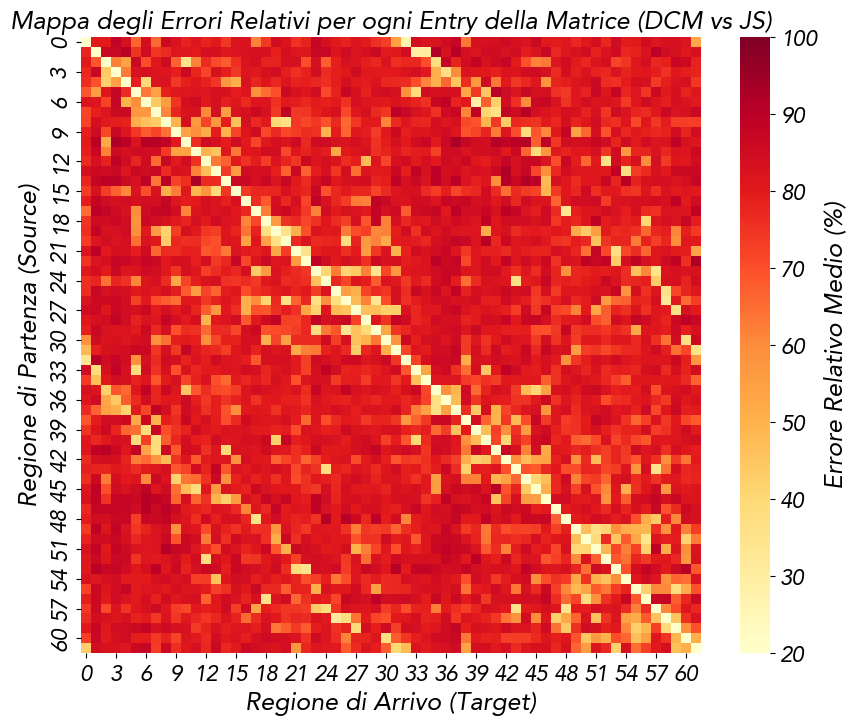

La connessione con il maggior disaccordo è dalla regione 22 alla regione 61
Errore medio in quel punto: 92.79%


In [61]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Inizializziamo una matrice 62x62 per accumulare gli errori percentuali
matrice_errori_totale = np.zeros((62, 62))

for t in range(144):
    # Estrai e rimuovi la diagonale
    matrice_JS = dediag(JS[indici, :62, :62][t])
    matrice_EC = dediag(ec_dcm[t].T)
    
    # Differenza assoluta cella per cella
    diff_assoluta = np.abs(matrice_JS - matrice_EC)
    
    # Normalizzazione Simmetrica (evita divisioni per zero e blocca l'errore max al 100%)
    somma_valori = np.abs(matrice_JS) + np.abs(matrice_EC)
    
    # Calcola la percentuale solo dove la somma è maggiore di zero
    err_percentuale = np.zeros((62, 62))
    maschera = somma_valori > 0
    err_percentuale[maschera] = (diff_assoluta[maschera] / somma_valori[maschera]) * 100
    
    # Accumula l'errore di questa istanza
    matrice_errori_totale += err_percentuale

# Fai la media sulle 144 istanze
matrice_errore_medio = matrice_errori_totale / 144

# Grafico Heatmap per vedere istantaneamente dove si concentrano gli errori
plt.figure(figsize=(10, 8))
sns.heatmap(matrice_errore_medio, cmap="YlOrRd", vmin=20, vmax=100, 
            cbar_kws={'label': 'Errore Relativo Medio (%)'})
plt.title("Mappa degli Errori Relativi per ogni Entry della Matrice (DCM vs JS)")
plt.xlabel("Regione di Arrivo (Target)")
plt.ylabel("Regione di Partenza (Source)")
plt.show()

# Trova le coordinate (riga, colonna) della connessione peggiore
riga_max, col_max = np.unravel_index(np.argmax(matrice_errore_medio), matrice_errore_medio.shape)
print(f"La connessione con il maggior disaccordo è dalla regione {riga_max} alla regione {col_max}")
print(f"Errore medio in quel punto: {matrice_errore_medio[riga_max, col_max]:.2f}%")


In [54]:
err_percentuale.shape

(62, 62)

(array([  96.,   34.,   36.,   42.,   35.,   57.,   33.,   37.,   43.,
          46.,   44.,   45.,   40.,   47.,   41.,   52.,   56.,   48.,
          57.,   48.,   43.,   43.,   47.,   53.,   57.,   45.,   39.,
          51.,   34.,   32.,   43.,   41.,   49.,   63.,   51.,   80.,
         103.,  143.,  205., 1685.]),
 array([  0. ,   2.5,   5. ,   7.5,  10. ,  12.5,  15. ,  17.5,  20. ,
         22.5,  25. ,  27.5,  30. ,  32.5,  35. ,  37.5,  40. ,  42.5,
         45. ,  47.5,  50. ,  52.5,  55. ,  57.5,  60. ,  62.5,  65. ,
         67.5,  70. ,  72.5,  75. ,  77.5,  80. ,  82.5,  85. ,  87.5,
         90. ,  92.5,  95. ,  97.5, 100. ]),
 <BarContainer object of 40 artists>)

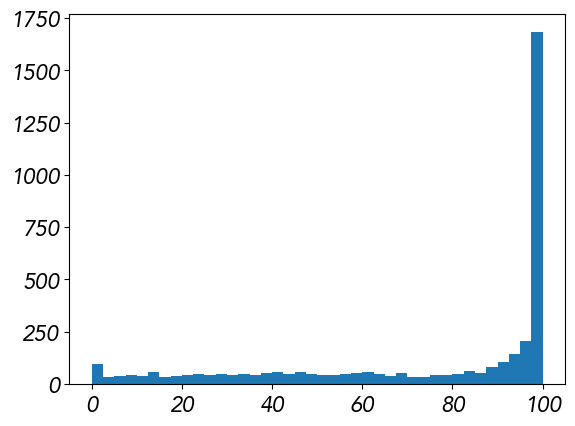

In [58]:
plt.hist(err_percentuale.flatten(), bins=40)

In [42]:
from scipy import stats
for i in range(144):
    print(np.linalg.norm(dediag(JS[indici,:62,:62][i])-dediag(ec_dcm[i].T),2)/np.linalg.norm(dediag(JS[indici,:62,:62][i]),2)*100)
#for i in range(62):
#    for j in range(62):
#print(stats.ttest_1samp(JS[indici,i,j] -ec_dcm[:,j,i],0))

111.6096787969418
110.6574649312171
122.7959723935753
119.80097746129503
90.97631268135106
98.70569439965965
95.2478862828712
88.75412382251314
113.76572344787394
119.67722528350511
93.87650350872359
89.95659774580369
92.86605594591941
96.24811682621642
100.00362644528727
121.22325216879413
119.5902812430605
107.98160070793266
100.10382860220905
105.83377910627422
103.88947494971661
100.69188112295508
127.47979741783291
112.67063427930866
100.55741878767586
126.4617474855361
100.24217728233968
103.26102884034971
123.89694828396807
137.98992623294987
107.75649662242456
140.6374315018578
123.74408275752344
112.31534982510831
104.07368620242605
115.17333779690155
115.86947332136172
103.01445082664884
127.94395136878008
119.74969657076177
92.65552810551941
99.26859161575744
114.72856416463675
97.53776958827949
89.73758296386349
133.69377798138817
112.4396684360895
131.87019980000255
86.37316839134023
110.15779908699767
111.79916950592622
116.14863701061668
105.6415749663403
113.81208388051

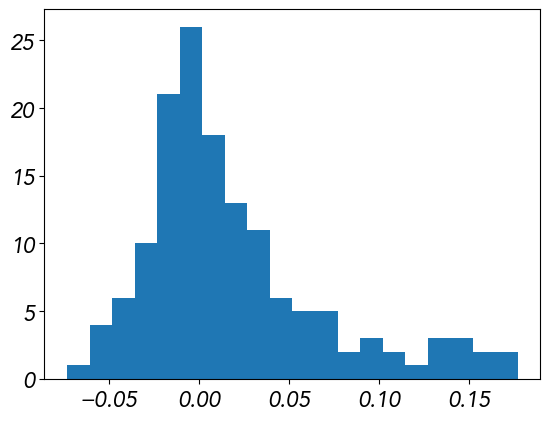

In [26]:
for i in [10]:
    plt.hist(JS[indici,40,30] -ec_dcm[:,30,40], bins=20)

Avenir


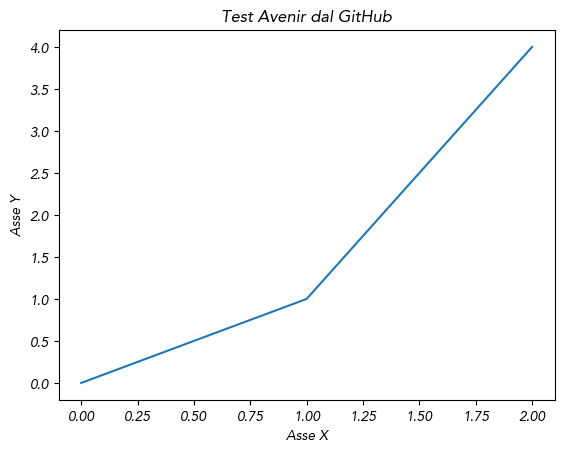

In [25]:
import urllib.request
from matplotlib import font_manager as fm
import matplotlib.pyplot as plt

# Link diretto al file TTF su GitHub (raw)
url = "https://github.com/omarwagih/scichat/raw/master/fonts/avenir/Avenir-Oblique.ttf"

# Salva localmente
font_file = "Avenir-Oblique.ttf"
urllib.request.urlretrieve(url, font_file)

# Registra il font in Matplotlib

fm.fontManager.addfont(font_file)

font_name = fm.FontProperties(fname=font_file).get_name()
print(font_name)
plt.rcParams["font.family"] = font_name

# Test plot
plt.figure()
plt.title("Test Avenir dal GitHub")
plt.xlabel("Asse X")
plt.ylabel("Asse Y")
plt.plot([0, 1, 2], [0, 1, 4])

In [18]:
maschera = np.zeros(1013)
indici =np.asarray(indici)

maschera[indici] = 1
maschera = maschera.astype(bool)
maschera[100]

JS[indici], JS[maschera]

(array([[[-1.42857143e+00,  6.10256616e-02,  2.86490238e-02, ...,
           1.74005562e-03,  2.11046455e-02, -1.23052129e-03],
         [ 6.00597627e-02, -1.42857143e+00,  2.42601059e-02, ...,
           1.94198034e-02, -4.87666656e-03, -2.28230629e-02],
         [ 3.31787980e-02,  2.44809904e-02, -1.42857143e+00, ...,
           6.81543211e-02,  1.35439222e-03,  2.79907316e-02],
         ...,
         [-4.28640149e-05, -3.99399000e-03,  5.49543089e-02, ...,
          -1.42857143e+00,  3.32690468e-03, -6.96164428e-03],
         [ 3.73861643e-03, -1.80672720e-02, -7.15966123e-03, ...,
          -7.53676766e-03, -1.42857143e+00,  1.38153651e-01],
         [-1.97028014e-02, -2.61206725e-02,  1.68721154e-02, ...,
          -1.60114406e-02,  1.19499160e-01, -1.42857143e+00]],
 
        [[-1.42857143e+00,  1.87438767e-02,  3.81266513e-02, ...,
           1.59566515e-02,  2.85393777e-03,  1.78081500e-03],
         [ 1.01118802e-02, -1.42857143e+00,  3.69573133e-02, ...,
           3.83745515

In [127]:


np.array_equal(JS[np.sort(indici)] , JS[maschera])

True

In [72]:
ec_dcm.shape

(144, 62, 62)

In [71]:
JS[maschera].shape,JS[indicia].shape

((144, 74, 74), (155, 74, 74))

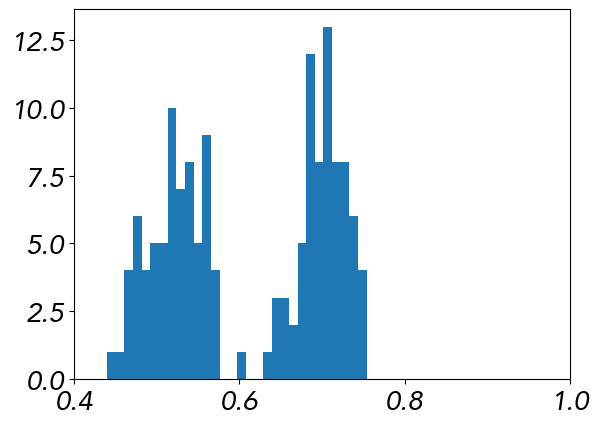

In [134]:

c=[]
for i in range(ec_dcm.shape[0]):
    mask = np.abs(JS_dcm[i,:,:])< 1e-2
    #mask = np.zeros((62,62))
    mask = np.logical_not(mask)
    corr=np.corrcoef(dediag(JS_dcm[i,:,:])[mask],dediag(JS[indicia][i,:,:].T)[mask])[0,1]
    c.append(corr)
plt.hist(c, bins =70);
plt.xlim(0.4,1);

sub-113215.mat_TR1_realData_var11_emo_points16.mat
sub-113215.mat_TR1_realData_var11_emo_points16.mat
yes
0.84
1.4893635690531346 0.89


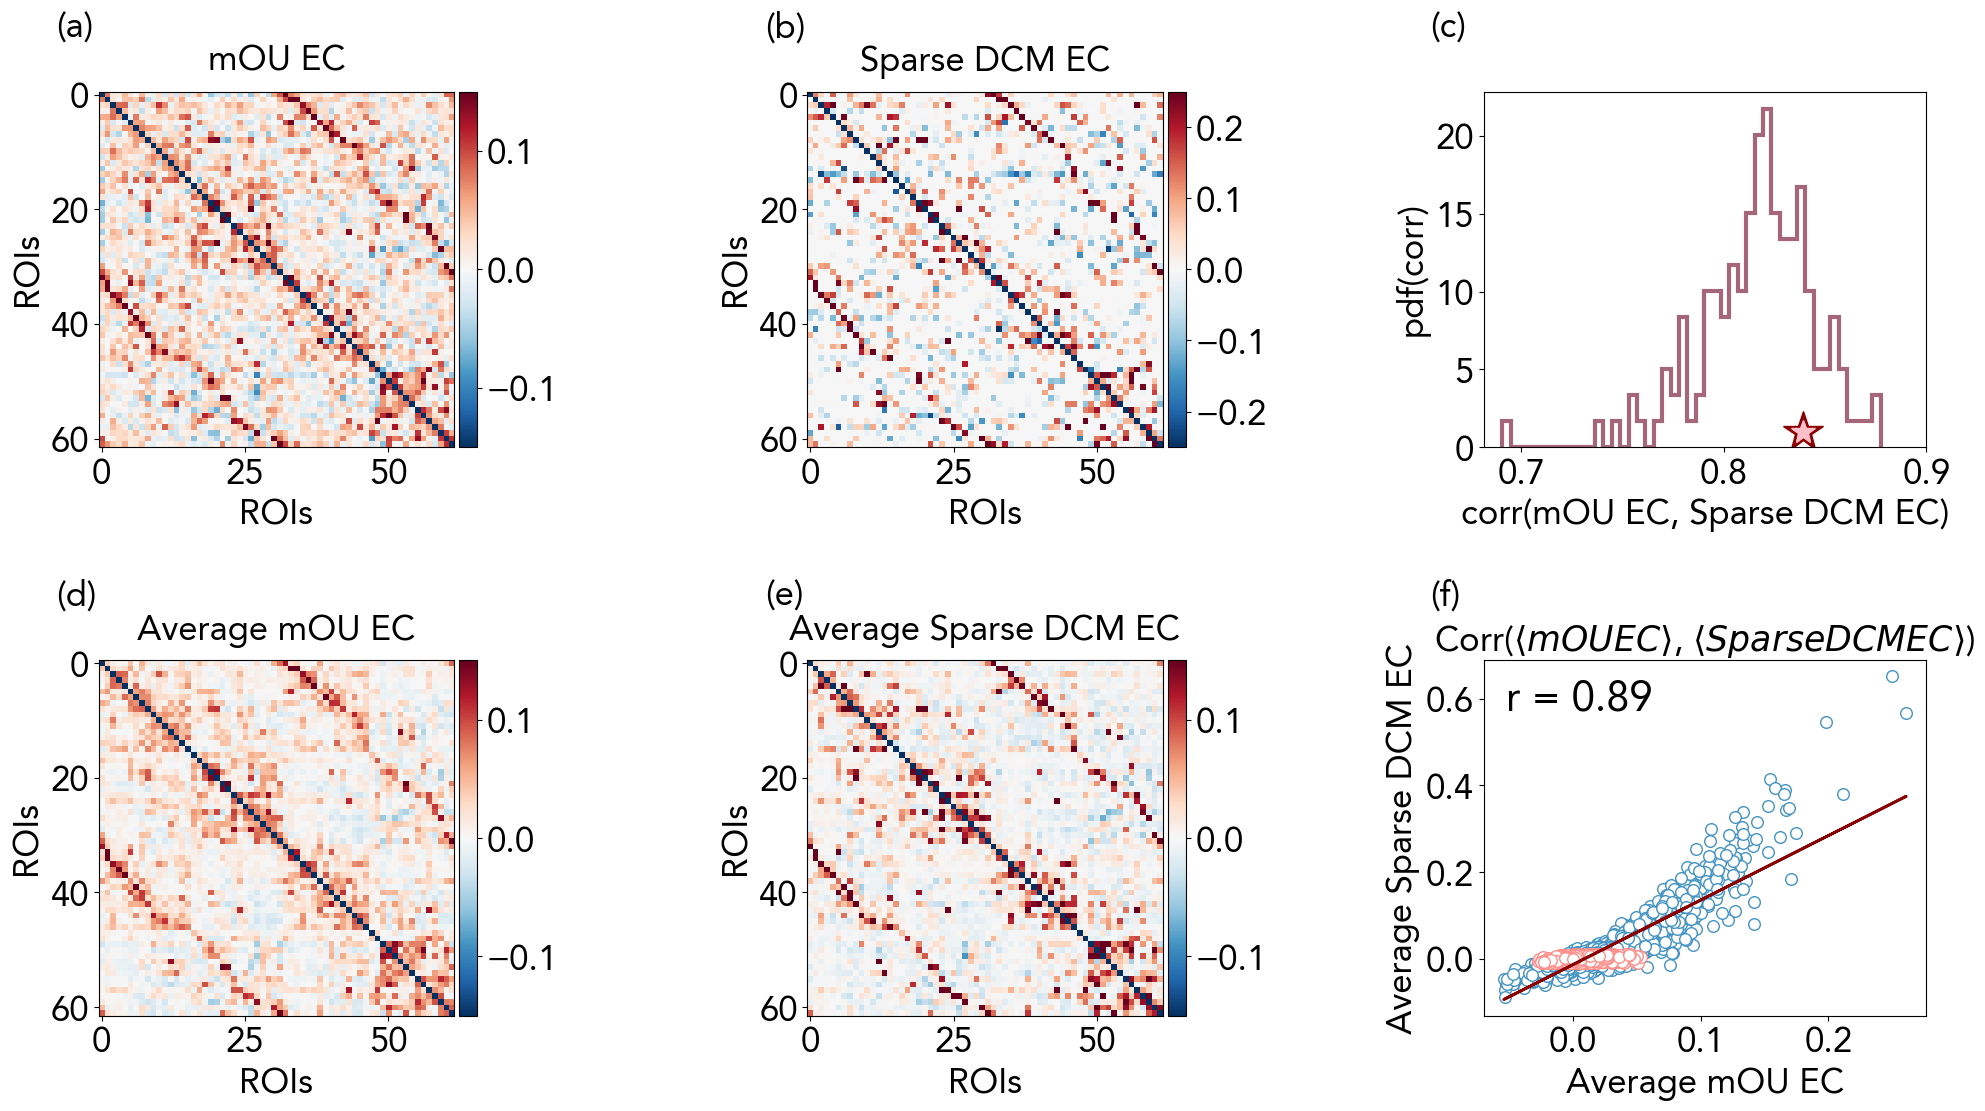

In [54]:
# Crea figura con 1 riga e 3 colonne
plt.rcParams['font.size'] = 23

from scipy.stats import linregress
from matplotlib import cm
colors = cm.RdBu_r(np.linspace(0,1,10))
fig, axes = plt.subplots(2, 3, figsize=(24,12)  )
from mpl_toolkits.axes_grid1 import make_axes_locatable
#subject = 44
#12
JS = np.load('numpy files/EC_matrix_HCP1_74.npy')

plt.rcParams["axes.titlesize"] = 25
plt.rcParams["axes.labelsize"] = 25
plt.rcParams["xtick.labelsize"] = 25
plt.rcParams["ytick.labelsize"] = 25

for i in os.listdir('../../codici/results')[134:135]:#19
    print(i)
    if 'TR1_realData_var11_emo_points16.' in i:
        print(i)
        sub_ = i[4:10]
        
        a = loadmat(f'../../codici/results/sub-{sub_}.mat_TR1_realData_var11_emo_points16.mat')['A']
        if a.shape[0] ==62:
            print('yes')
            sub_tot= np.asarray(sub_tot)
            index = np.where(sub_tot == sub_)[0][0]

# Primo pannello
v = [0.15,0.25]
#mat = loadmat(pat + np.sort(os.listdir('/readonly/insights/RESULTS_YA_new_1000/RESULTS_YA_new_1000_RUN1_noisevar/'))[subject])['A']
js=[JS[index,:62,:62],a.T]

titles = ['mOU EC', 'Sparse DCM EC',]
for i,ax in enumerate(axes.reshape(-1)[:2]):
    im= ax.imshow(js[i], vmin=-v[i], vmax=v[i], cmap = 'RdBu_r');
    divider = make_axes_locatable(ax)
    cax = divider.append_axes('right', size='5%', pad=0.05)
    fig.colorbar(im, cax=cax, orientation='vertical')
    ax.set_title(f"{titles[i]}",pad=15)
    ax.set_xlabel('ROIs')
    ax.set_ylabel('ROIs')
    

x = (dediag(js[0]))
y = (dediag(js[1]))
mask = np.abs(y)<1e-2

val = (np.corrcoef(x[np.logical_not(mask)].flatten(),y[np.logical_not(mask)].flatten())[0,1])
axes[0,2].hist(c, bins = 45, color ='white', edgecolor =colors[-1],lw = 3, histtype = 'step', density =True,alpha=.6);
#axes[0,2].scatter(val, 3, marker='*', color='pink',edgecolor='darkred', s = 500, alpha=1);
axes[0,2].plot(val, 1, marker='*', color='darkred', ms =30)# alpha=1);
axes[0,2].plot(val, 1, marker='*', color='pink', ms =18)# alpha=1);
axes[0,2].set_xticks([0.7,0.8,0.9])


axes[0,2].set_xlabel('corr(mOU EC, Sparse DCM EC)')
axes[0,2].set_ylabel('pdf(corr)')


print(round(val,2))

from scipy import stats

v = [0.15,0.15]
#mat = loadmat(pat + np.sort(os.listdir('/readonly/insights/RESULTS_YA_new_1000/RESULTS_YA_new_1000_RUN1_noisevar/'))[subject])['A']
js=[np.mean(JS[maschera][:,:62,:62],0),np.mean(ec_dcm,0).T]

#js =[JS[subject][:62,:62], JS_100_1[subject][:100,:100], JS_200_1[subject][:200,:200], JS[subject][:62,:62],cluster_regions_EC(JS_100_1[subject][:100,:100], aggregate[:100]), cluster_regions_EC(mapping_100_200(JS_200_1[subject][:200,:200]), aggregate[:100])]

titles = ['Average mOU EC', 'Average Sparse DCM EC',]
for i,ax in enumerate(axes.reshape(-1)[3:5]):
    im= ax.imshow(js[i], vmin=-v[i], vmax=v[i], cmap = 'RdBu_r');
    divider = make_axes_locatable(ax)
    cax = divider.append_axes('right', size='5%', pad=0.05)
    fig.colorbar(im, cax=cax, orientation='vertical')
    ax.set_title(f"{titles[i]}",pad=15)
    ax.set_xlabel('ROIs')
    ax.set_ylabel('ROIs')
    


x = (dediag(js[0]))
y = (dediag(js[1]))
mask = np.abs(y)<0.01

x = (dediag(js[0]))[np.logical_not(mask)]
y = (dediag(js[1]))[np.logical_not(mask)]
res = linregress(x.flatten(), y.flatten())
slope, intercept, r, p = res.slope, res.intercept, round(res.rvalue,2), res.pvalue


im= axes[1,2].scatter(x,y,c = 'white',edgecolor ="#4393c3",s = 70) #(blu molto scuro))
#, vmin=-v[i], vmax=v[i], cmap = 'bwr');
y_line = slope * x.flatten() + intercept
axes[1,2].plot(x.flatten(), y_line, linewidth=2, color ='darkred')

x = dediag(js[0])[(mask)]
y = (dediag(js[1]))[(mask)]
im= axes[1,2].scatter(x,y,c = 'white',edgecolor = "#ff8f8a", s = 70)

print(slope, r)
from scipy import stats

axes[1,2].set_ylabel('Average Sparse DCM EC')
axes[1,2].set_xlabel('Avergage mOU EC') if i == 0 else axes[1,2].set_xlabel('Average mOU EC') 
axes[1,2].set_title(r"Corr($\langle mOU EC \rangle$, $\langle Sparse DCM EC \rangle$)")
# --- Testo dentro la figura ---
text_str = f"r = {r:.2f}"
axes[1,2].text(
    0.05, 0.95,              # posizione (fractions dell'asse)
    text_str,
    transform=axes[1,2].transAxes,  # usa coordinate normalizzate
    verticalalignment='top',
    fontsize=30,
    bbox=dict(facecolor='white', alpha=0.7, edgecolor='none')
    )

#plt.subplots_adjust(hspace=.8, wspace=.3)
plt.subplots_adjust(hspace=.6, wspace=.6)

#plt.tight_layout()
import string
labels = list(string.ascii_lowercase)  # a, b, c, d, ...

for ax, lab in zip(axes.flatten(), labels):
    ax.text(
        -0.12, 1.23,                 # posizione (fuori dall'asse)
        f"({lab})",
        transform=ax.transAxes,
        fontsize=25,
        fontweight='bold',
        va='top',
        ha='left'

        
    )
plt.savefig('Figures/comparison_w_hcp2.jpg', dpi = 300, bbox_inches ='tight');


In [58]:


c=[]
for i in range(JS_dcm.shape[0]):
    mask = np.abs(JS_dcm[i,:62,:62])< 1e-2
    mask = np.logical_not(mask)
    corr=np.corrcoef(dediag(JS_dcm[i,:62,:62])[mask],dediag(JS[indicia][i,:62,:62].T)[mask])[0,1]
    c.append(corr)

In [66]:
ec_dcm = np.asarray(ec_dcm)
ec_dcm.shape, JS[maschera].shape

((144, 62, 62), (144, 74, 74))

In [90]:
indici

array([  3,   2,  93,  91,  96,  95,  92,  97, 101,  90,  94, 102,  99,
       100,  98, 103, 105, 104, 106, 107, 109, 112, 110, 113, 111, 116,
       115, 118, 114, 119, 121, 117, 120, 125, 123, 122, 124, 143, 141,
       144, 137, 145, 136, 146, 147, 138, 151, 142, 156, 157, 161, 158,
       159, 163, 166, 160, 164, 162, 167, 173, 139, 168, 170, 171, 165,
       172, 175, 174, 177, 176, 186, 179, 187, 188, 178, 180,   4,  12,
        10,   7,   9,   8,  11,  13,  15,  18,  17,  14,  16,  20,  21,
        31,  19,  27,  24,  25,  26,  32,  22,  35,  34,  33,  36,  45,
        42,  40,  43,  44,  51,  49,  53,  46,  48,  54,  52,  55,  56,
        47,  57,  62,  64,  73,  76,  63,  72,  74,  59,  77,  50,  79,
        82,  75,  80,  58,  78,  65,  85,  83,  89,  81,  87,  84,  88,
        86])

In [86]:
len(np.unique(indici)), maschera.sum()

(144, np.int64(144))

In [89]:
np.array_equal(JS[maschera][0],JS[indici][0])

False

In [118]:

c=[]
for i in range(JS_dcm[:73].shape[0]):
    mask = np.abs(JS_dcm[i,:62,:62])< 1e-2
    mask = np.logical_not(mask)
    corr=np.corrcoef(dediag(JS_dcm[i,:62,:62])[mask],dediag(JS[indicia][i,:62,:62].T)[mask])[0,1]
    c.append(corr)

(0.6, 1.0)

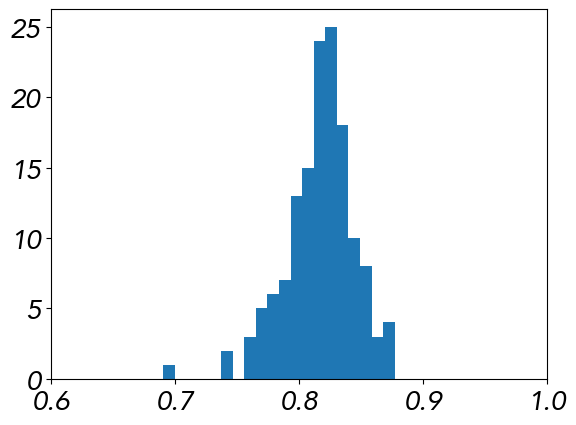

In [125]:

c=[]
for i in range(ec_dcm[:].shape[0]):
    mask = np.abs(ec_dcm[i,:62,:62])< 1e-2
   # mask = np.zeros((62,62))
    mask = np.logical_not(mask)
    corr=np.corrcoef(dediag(ec_dcm[i,:62,:62])[mask],dediag(JS[indici][i,:62,:62].T)[mask])[0,1]
    c.append(corr)
plt.hist(c, bins =20);
plt.xlim(0.6,1)

(0.6, 1.0)

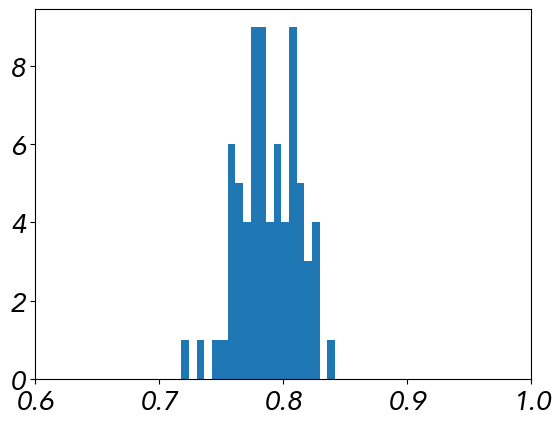

In [120]:
plt.hist(c, bins =20);
plt.xlim(0.6,1)

1.3518688839150461 0.91


/tmp/ipykernel_74886/3827695046.py:128: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(hspace=.4, wspace=.6)


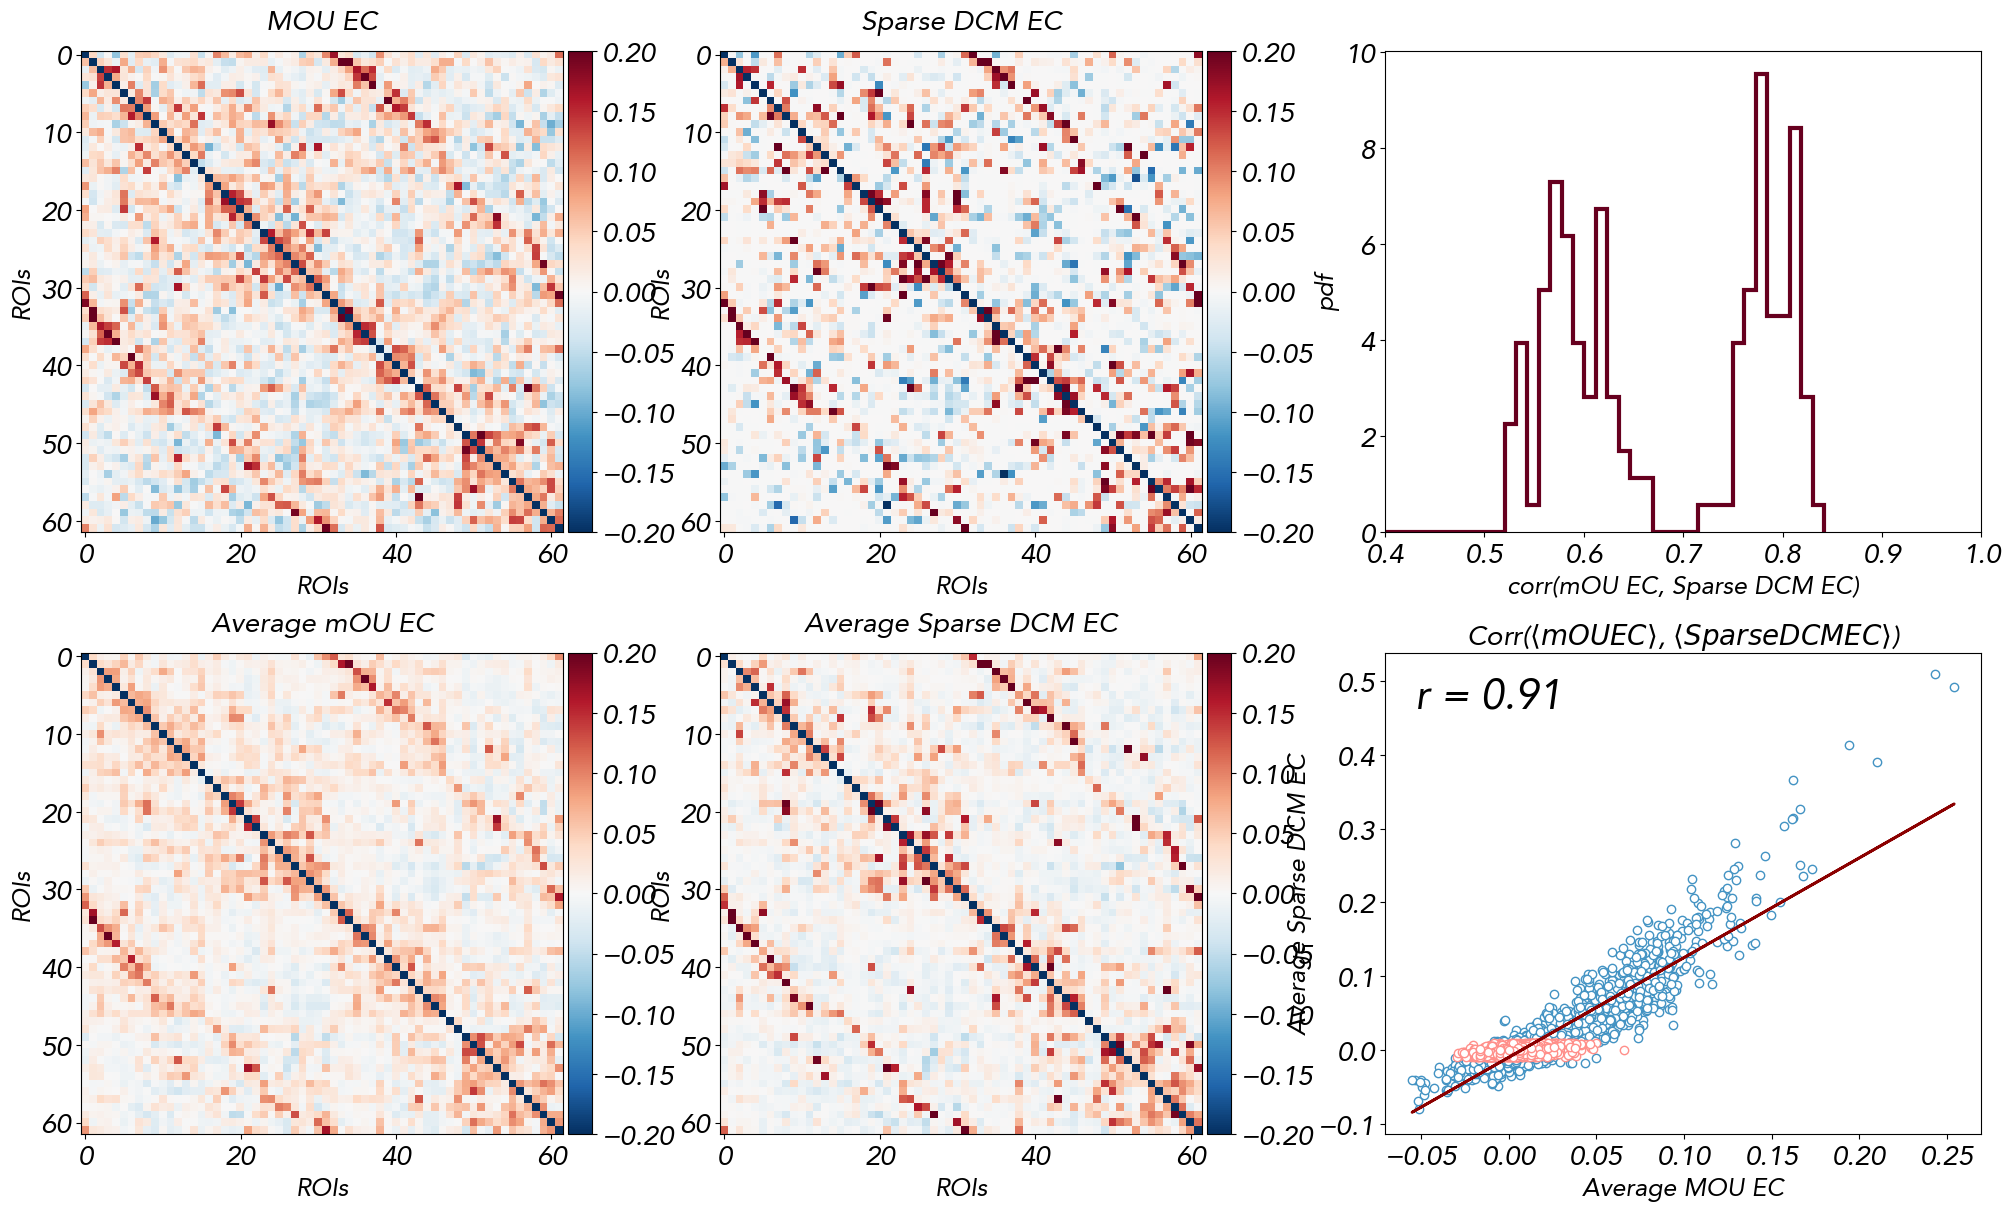

In [56]:
# Crea figura con 1 riga e 3 colonne
fig, axes = plt.subplots(2, 3, figsize=(20,12) , constrained_layout=True)
from mpl_toolkits.axes_grid1 import make_axes_locatable
#subject = 44

from matplotlib import cm
colors = cm.RdBu_r(np.linspace(0,1,10))
#12

plt.rcParams["axes.titlesize"] = 20
plt.rcParams["axes.labelsize"] = 18
plt.rcParams["xtick.labelsize"] = 20
plt.rcParams["ytick.labelsize"] = 20

# Primo pannello
v = [0.2,0.2]
#mat = loadmat(pat + np.sort(os.listdir('/readonly/insights/RESULTS_YA_new_1000/RESULTS_YA_new_1000_RUN1_noisevar/'))[subject])['A']
js=[JS[indicia,:62,:62][2],JS_dcm[2,:62,:62].T]

#js =[JS[subject][:62,:62], JS_100_1[subject][:100,:100], JS_200_1[subject][:200,:200], JS[subject][:62,:62],cluster_regions_EC(JS_100_1[subject][:100,:100], aggregate[:100]), cluster_regions_EC(mapping_100_200(JS_200_1[subject][:200,:200]), aggregate[:100])]

titles = ['MOU EC', 'Sparse DCM EC',]
for i,ax in enumerate(axes.reshape(-1)[:2]):
    im= ax.imshow(js[i], vmin=-v[i], vmax=v[i], cmap = 'RdBu_r');
    divider = make_axes_locatable(ax)
    cax = divider.append_axes('right', size='5%', pad=0.05)
    fig.colorbar(im, cax=cax, orientation='vertical')
    ax.set_title(f"{titles[i]}",pad=15)
    ax.set_xlabel('ROIs')
    ax.set_ylabel('ROIs')
    
    

c=[]
for i in range(JS_dcm[:].shape[0]):
    mask = np.abs(JS_dcm[i,:62,:62])< 1e-2
    mask = np.logical_not(mask)
    corr=np.corrcoef(dediag(JS_dcm[i,:62,:62])[mask],dediag(JS[indicia][i,:62,:62].T)[mask])[0,1]
    c.append(corr)


axes[0,2].hist(c, bins = 70, color ='white', edgecolor =colors[-1],lw = 3, histtype = 'step', density =True);
axes[0,2].set_xlabel('corr(mOU EC, Sparse DCM EC)')
axes[0,2].set_ylabel('pdf')
axes[0,2].set_xlim(0.4,1)


#print(slope, r)
from scipy import stats
#res = stats.spearmanr(x.flatten(), y.flatten())
# Titolo completo
#print('sp', res)
#axes[0,2].set_title(f"{titles[i]}")
#axes[0,2].set_ylabel('Sparse DCM EC')
#axes[0,2].set_xlabel('MOU EC') if i == 0 else axes[0,2].set_xlabel('MOU EC') 

# Primo pannello
v = [0.2,0.2]
#mat = loadmat(pat + np.sort(os.listdir('/readonly/insights/RESULTS_YA_new_1000/RESULTS_YA_new_1000_RUN1_noisevar/'))[subject])['A']
js=[np.mean(JS[indicia,:62,:62][:73],0).T,np.mean(JS_dcm[:73,:62,:62],0)]

#js =[JS[subject][:62,:62], JS_100_1[subject][:100,:100], JS_200_1[subject][:200,:200], JS[subject][:62,:62],cluster_regions_EC(JS_100_1[subject][:100,:100], aggregate[:100]), cluster_regions_EC(mapping_100_200(JS_200_1[subject][:200,:200]), aggregate[:100])]

titles = ['Average mOU EC', 'Average Sparse DCM EC',]
for i,ax in enumerate(axes.reshape(-1)[3:5]):
    im= ax.imshow(js[i], vmin=-v[i], vmax=v[i], cmap = 'RdBu_r');
    divider = make_axes_locatable(ax)
    cax = divider.append_axes('right', size='5%', pad=0.05)
    fig.colorbar(im, cax=cax, orientation='vertical')
    ax.set_title(f"{titles[i]}",pad=15)
    ax.set_xlabel('ROIs')
    ax.set_ylabel('ROIs')
    


x = (dediag(js[0]))

y = (dediag(js[1]))
mask = np.abs(y)<1e-2


x = (dediag(js[0]))[np.logical_not(mask)]
y = (dediag(js[1]))[np.logical_not(mask)]

res = linregress(x.flatten(), y.flatten())
slope, intercept, r, p = res.slope, res.intercept, round(res.rvalue,2), res.pvalue


im= axes[1,2].scatter(x,y,c = 'white',edgecolor ="#4393c3") #(blu molto scuro))
#, vmin=-v[i], vmax=v[i], cmap = 'bwr');


y_line = slope * x.flatten() + intercept
axes[1,2].plot(x.flatten(), y_line, linewidth=2, color ='darkred')

x = dediag(js[0])[(mask)]
y = (dediag(js[1]))[(mask)]



im= axes[1,2].scatter(x,y,c = 'white',edgecolor = "#ff8f8a"
              )

print(slope, r)
from scipy import stats
#res = stats.spearmanr(x.flatten(), y.flatten())
# Titolo completo
#print('sp', res)
axes[1,2].set_title(r"Corr($\langle mOU EC \rangle$, $\langle Sparse DCM EC \rangle$)")
axes[1,2].set_ylabel('Average Sparse DCM EC')
axes[1,2].set_xlabel('Avergage MOU EC') if i == 0 else axes[1,2].set_xlabel('Average MOU EC') 





# --- Testo dentro la figura ---
text_str = f"r = {r:.2f}"
axes[1,2].text(
    0.05, 0.95,              # posizione (fractions dell'asse)
    text_str,
    transform=axes[1,2].transAxes,  # usa coordinate normalizzate
    verticalalignment='top',
    fontsize=30,
    bbox=dict(facecolor='white', alpha=0.7, edgecolor='none')
    )
#plt.tight_layout()
plt.subplots_adjust(hspace=.4, wspace=.6)


#plt.savefig('Figures/comparison_w_hcp.jpg', dpi = 300, bbox_inches ='tight');

In [25]:
JS_dcm.shape


(155, 74, 74)

In [42]:
JS = np.load('numpy files/EC_matrix_HCP1_74.npy')
JS_dcm = np.load('numpy files/EC_dcm_HCP1_74.npy')

In [106]:
JS2= np.load('../../numpy files/EC_matrix_HCP2_74.npy')


In [105]:
np.save('../../numpy files/EC_dcm_HCP2_74.npy', mat_dcm)

In [104]:
mat_dcm = np.asarray(mat_dcm)
mat_dcm.shape

(170, 74, 74)

In [103]:
#corr=[]
mat_dcm =[]
#js____ = JS_2[indicia]
for subject in range(len(indicia)):
    mat = loadmat(pat + np.sort(os.listdir('/readonly/insights/RESULTS_YA_new_1000/RESULTS_YA_new_1000_RUN2/'))[subject])['A']
    #js=[js____[subject], mat_dcm[subject].T]
    mat_dcm.append(mat)

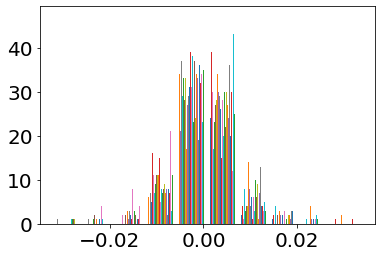

In [121]:
plt.hist((dediag(np.mean(mat_dcm[:80],0)) -dediag(np.mean(mat_dcm[80:],0))));

In [124]:
(np.abs(np.mean(mat_dcm[80:],0)) <1e-2).sum()

3183

In [7]:
ikk1=[]
import os
pat = '/readonly/insights/RESULTS_YA_new_1000/RESULTS_YA_new_1000_RUN1_noisevar/'
for i in os.listdir('/readonly/insights/RESULTS_YA_new_1000/RESULTS_YA_new_1000_RUN1_noisevar/'):
    if i[-10:-4] in sub_tot:
        ikk1.append(i[-10:-4])
        
ikk1 = np.sort(ikk1)

In [10]:
 len(ikk1),#ikk[:4], ikk1[:4]

(155,)

In [20]:
ikk=[]
pat = '/readonly/insights/RESULTS_YA_new_1000/RESULTS_YA_new_1000_RUN2'
for i in os.listdir('/readonly/insights/RESULTS_YA_new_1000/RESULTS_YA_new_1000_RUN2'):
    if i[-10:-4] in sub_tot:
        ikk.append(i[-10:-4])
        
ikk = np.sort(ikk)
kkk =[]
nnt=[]
for i in range(len(ikk1)):
    a = np.where(ikk1[i]==ikk)[0]
    if len(a)>0:
        kkk.append(a[0])
    else:
        nnt.append(i)
len(kkk)

144

In [164]:
len(JS_dcm[mask_1])

144

In [161]:
mask_1 = np.ones(len(JS_dcm))
mask_1[np.array(nnt)] =0

In [169]:
np.array(list(map(dediag,JS_dcm[mask_1]))).shape

(144, 74, 74)

In [180]:
C = np.corrcoef(np.array(list(map(dediag,JS_dcm[mask_1]))).reshape(144,-1), np.array(list(map(dediag,mat_dcm[kkk]))).reshape(144,-1))[:N, N:]

In [2]:
ikk=[]
pat = '/readonly/insights/RESULTS_YA_new_1000/RESULTS_YA_new_1000_RUN1_noisevar/'
for i in os.listdir('/readonly/insights/RESULTS_YA_new_1000/RESULTS_YA_new_1000_RUN1_noisevar/'):
    if i[-10:-4] in sub_tot:
        ikk.append(i[-10:-4])
sub_tot = np.asarray(sub_tot)        
ikk = np.sort(ikk)
indicia = np.asarray([np.where(ikk[i]==sub_tot)[0] for i in range(len(ikk))]).reshape(-1)
len(indicia)

NameError: name 'os' is not defined

1.1755729075883596 0.71


Text(0.05, 0.95, 'r = 0.71')

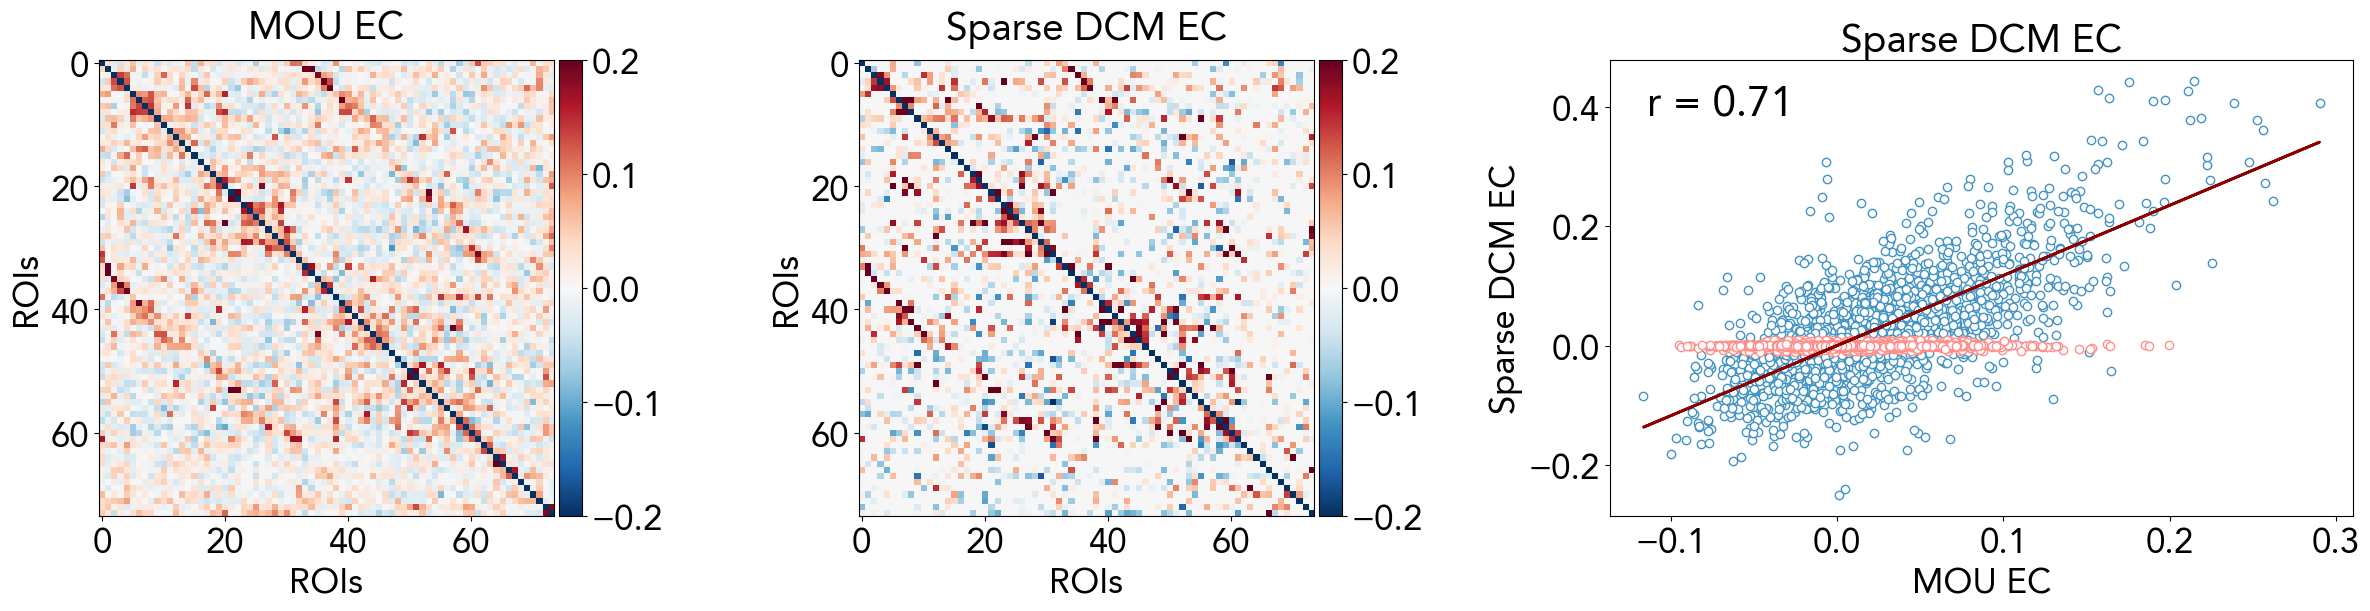

In [41]:
# Crea figura con 1 riga e 3 colonne
fig, axes = plt.subplots(1, 3, figsize=(24,6)  ,constrained_layout=True)
from mpl_toolkits.axes_grid1 import make_axes_locatable
subject = 44
#12

plt.rcParams["axes.titlesize"] = 28
plt.rcParams["axes.labelsize"] = 25
plt.rcParams["xtick.labelsize"] = 25
plt.rcParams["ytick.labelsize"] = 25



# Primo pannello
v = [0.2,0.2]
mat = loadmat(pat + np.sort(os.listdir('/readonly/insights/RESULTS_YA_new_1000/RESULTS_YA_new_1000_RUN1_noisevar/'))[subject])['A']
js=[JS[indicia][subject], mat.T]

#js =[JS[subject][:62,:62], JS_100_1[subject][:100,:100], JS_200_1[subject][:200,:200], JS[subject][:62,:62],cluster_regions_EC(JS_100_1[subject][:100,:100], aggregate[:100]), cluster_regions_EC(mapping_100_200(JS_200_1[subject][:200,:200]), aggregate[:100])]

titles = ['MOU EC', 'Sparse DCM EC',]
for i,ax in enumerate(axes.reshape(-1)[:2]):
    im= ax.imshow(js[i], vmin=-v[i], vmax=v[i], cmap = 'RdBu_r');
    divider = make_axes_locatable(ax)
    cax = divider.append_axes('right', size='5%', pad=0.05)
    fig.colorbar(im, cax=cax, orientation='vertical')
    ax.set_title(f"{titles[i]}",pad=15)
    ax.set_xlabel('ROIs')
    ax.set_ylabel('ROIs')
    


x = (dediag(js[0]))

y = (dediag(js[1]))
mask = np.abs(y)<1e-2


x = (dediag(js[0]))[np.logical_not(mask)]
y = (dediag(js[1]))[np.logical_not(mask)]

res = linregress(x.flatten(), y.flatten())
slope, intercept, r, p = res.slope, res.intercept, round(res.rvalue,2), res.pvalue


im= axes[-1].scatter(x,y,c = 'white',edgecolor ="#4393c3") #(blu molto scuro))
#, vmin=-v[i], vmax=v[i], cmap = 'bwr');


y_line = slope * x.flatten() + intercept
axes[-1].plot(x.flatten(), y_line, linewidth=2, color ='darkred')

x = dediag(js[0])[(mask)]
y = (dediag(js[1]))[(mask)]



im= axes[-1].scatter(x,y,c = 'white',edgecolor = "#ff8f8a"
              )

print(slope, r)
from scipy import stats
#res = stats.spearmanr(x.flatten(), y.flatten())
# Titolo completo
#print('sp', res)
axes[-1].set_title(f"{titles[i]}")
axes[-1].set_ylabel('Sparse DCM EC')
axes[-1].set_xlabel('MOU EC') if i == 0 else axes[-1].set_xlabel('MOU EC') 

# --- Testo dentro la figura ---
text_str = f"r = {r:.2f}"
axes[-1].text(
    0.05, 0.95,              # posizione (fractions dell'asse)
    text_str,
    transform=axes[-1].transAxes,  # usa coordinate normalizzate
    verticalalignment='top',
    fontsize=30,
    bbox=dict(facecolor='white', alpha=0.7, edgecolor='none')
    )

#plt.savefig('Figures/Comparison.jpg', dpi = 300, bbox_inches='tight');

In [19]:
plt.rcParams['font.size']=30

In [42]:
matt = JS_dcm

1.3218723229393043 0.91


Text(0.05, 0.95, 'r = 0.91')

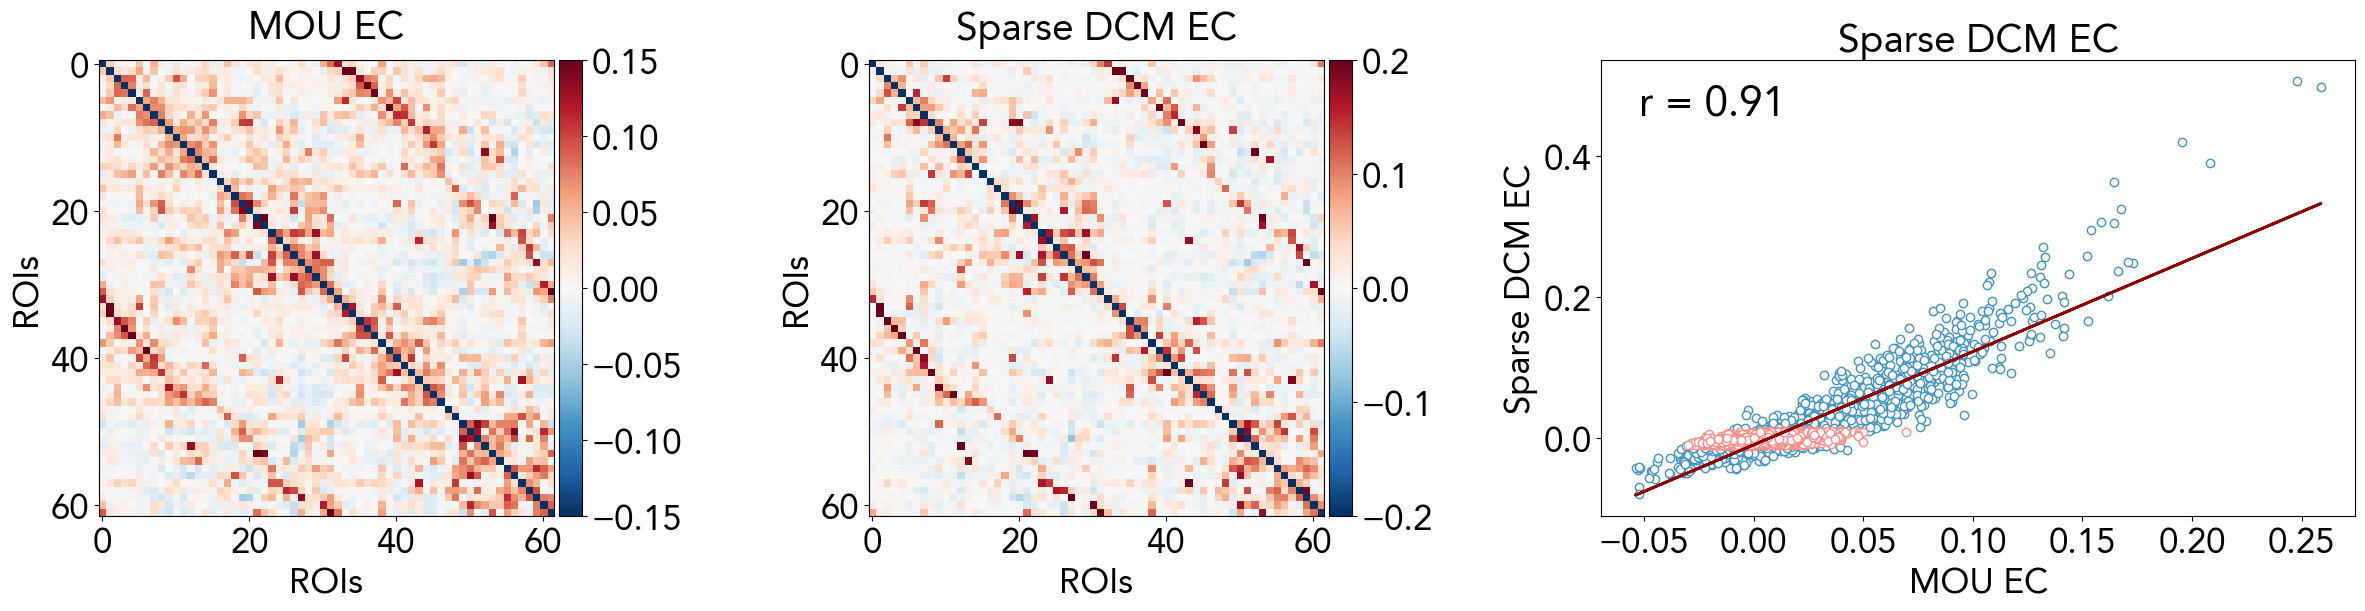

In [46]:
# Crea figura con 1 riga e 3 colonne
fig, axes = plt.subplots(1, 3, figsize=(24,6)  ,constrained_layout=True)
from mpl_toolkits.axes_grid1 import make_axes_locatable
subject = 12

plt.rcParams["axes.titlesize"] = 28
plt.rcParams["axes.labelsize"] = 25
plt.rcParams["xtick.labelsize"] = 25
plt.rcParams["ytick.labelsize"] = 25



# Primo pannello
v = [0.15,0.2]
#mat = loadmat(pat + np.sort(os.listdir('/readonly/insights/RESULTS_YA_new_1000/RESULTS_YA_new_1000_RUN1_noisevar/'))[subject])['A']
js=[np.mean(JS[indicia][:,:62,:62],0), np.mean(matt[:,:62,:62],0).T]

#js =[JS[subject][:62,:62], JS_100_1[subject][:100,:100], JS_200_1[subject][:200,:200], JS[subject][:62,:62],cluster_regions_EC(JS_100_1[subject][:100,:100], aggregate[:100]), cluster_regions_EC(mapping_100_200(JS_200_1[subject][:200,:200]), aggregate[:100])]

titles = ['MOU EC', 'Sparse DCM EC',]
for i,ax in enumerate(axes.reshape(-1)[:2]):
    im= ax.imshow(js[i], vmin=-v[i], vmax=v[i], cmap = 'RdBu_r');
    divider = make_axes_locatable(ax)
    cax = divider.append_axes('right', size='5%', pad=0.05)
    fig.colorbar(im, cax=cax, orientation='vertical')
    ax.set_title(f"{titles[i]}",pad=15)
    ax.set_xlabel('ROIs')
    ax.set_ylabel('ROIs')
    


x = (dediag(js[0]))

y = (dediag(js[1]))
mask = np.abs(y)<1e-2


x = (dediag(js[0]))[np.logical_not(mask)]
y = (dediag(js[1]))[np.logical_not(mask)]

res = linregress(x.flatten(), y.flatten())
slope, intercept, r, p = res.slope, res.intercept, round(res.rvalue,2), res.pvalue


im= axes[-1].scatter(x,y,c = 'white',edgecolor ="#4393c3") #(blu molto scuro))
#, vmin=-v[i], vmax=v[i], cmap = 'bwr');


y_line = slope * x.flatten() + intercept
axes[-1].plot(x.flatten(), y_line, linewidth=2, color ='darkred')

x = dediag(js[0])[(mask)]
y = (dediag(js[1]))[(mask)]



im= axes[-1].scatter(x,y,c = 'white',edgecolor = "#ff8f8a"
              )

print(slope, r)
from scipy import stats
#res = stats.spearmanr(x.flatten(), y.flatten())
# Titolo completo
#print('sp', res)
axes[-1].set_title(f"{titles[i]}")
axes[-1].set_ylabel('Sparse DCM EC')
axes[-1].set_xlabel('MOU EC') if i == 0 else axes[-1].set_xlabel('MOU EC') 

# --- Testo dentro la figura ---
text_str = f"r = {r:.2f}"
axes[-1].text(
    0.05, 0.95,              # posizione (fractions dell'asse)
    text_str,
    transform=axes[-1].transAxes,  # usa coordinate normalizzate
    verticalalignment='top',
    fontsize=30,
    bbox=dict(facecolor='white', alpha=0.7, edgecolor='none')
    )


#plt.savefig('Figures/Comparison_av.jpg', dpi = 300, bbox_inches='tight');

In [45]:
JS[indicia].shape

(155, 74, 74)

In [232]:
JS_2 = np.load('numpy files/EC_matrix_HCP2_74.npy')
JS = np.load('numpy files/EC_matrix_HCP1_74.npy')
matt =  np.asarray(matt)
JS_2.shape, np.asarray(matt).shape, JS.shape, mat_dcm.shape

NameError: name 'matt' is not defined

In [18]:
ikk=[]
pat = '/readonly/insights/RESULTS_YA_new_1000/RESULTS_YA_new_1000_RUN2/'
for i in os.listdir('/readonly/insights/RESULTS_YA_new_1000/RESULTS_YA_new_1000_RUN2/'):
    if i[-10:-4] in sub_tot:
        ikk.append(i[-10:-4])
#ikk
len(ikk)
ikk[:10]
sub_tot=np.asarray(sub_tot)
ikk = np.sort(ikk)
indicia = np.asarray([np.where(ikk[i]==sub_tot)[0] for i in range(len(ikk))]).reshape(-1)
indicia.shape

(170,)

In [24]:
ikk = np.sort(ikk)
sub_tot = np.asarray(sub_tot)
i=0
np.where(ikk[i]==sub_tot)[0]

array([2])

In [15]:
ikk=[]
pat = '/readonly/insights/RESULTS_YA_new_1000/RESULTS_YA_new_1000_RUN1_noisevar/'
for i in os.listdir('/readonly/insights/RESULTS_YA_new_1000/RESULTS_YA_new_1000_RUN1_noisevar/'):
    if i[-10:-4] in sub_tot:
        ikk.append(i[-10:-4])
#ikk
len(ikk)
ikk[:10]
ikk = np.sort(ikk)
indicia = np.asarray([np.where(ikk[i]==sub_tot)[0] for i in range(len(ikk))]).reshape(-1)
indicia.shape

(155,)

In [437]:
#(os.listdir('/readonly/insights/RESULTS_YA_new_1000/RESULTS_YA_new_1000_RUN1_noisevar/'))
pat

'/readonly/insights/RESULTS_YA_new_1000/RESULTS_YA_new_1000_RUN1_noisevar/'

In [42]:
ls 'numpy files'

 dcm_sorted.npy                     EC_ms_mask_minC.npy
 EC_dcm_HCP1_74.npy                 ec_ms_new_100.npy
 EC_hc_200.npy                      ec_ms_new_62.npy
 EC_hc_ihmask.npy                   ec_ms_new_72.npy
 EC_hc_mask_minC.npy                ec_ms_new_cov.npy
 EC_hc_not_mask.npy                 ec_ms_new.npy
 EC_hc.npy                          EC_ms_not_mask.npy
 EC_matrix_HCP1_100.npy             EC_ms.npy
 EC_matrix_HCP1_200_converged.npy   ecs_dcm_ms.npy
 EC_matrix_HCP1_200.npy            'ec + sub.npy'
 EC_matrix_HCP1_74.npy              matrici_dcm_HCP_corr.npy
 EC_matrix_HCP2_100.npy             matrici_MOU_corr.npy
 EC_matrix_HCP2_200_converged.npy   matrici_MOU_HCP_corr.npy
 EC_matrix_HCP2_200.npy             matrici_MOU.npy
 EC_matrix_HCP2_74.npy              mean_EC_200.npy
 EC_ms_200.npy                      mou_sorted.npy
 EC_ms_ihmask.npy


In [45]:
matt = np.load('numpy files/EC_dcm_HCP1_74.npy')

In [36]:
mat_dcm=np.asarray(mat_dcm)

In [555]:
np.save('numpy files/EC_dcm_HCP1_74.npy', mat_dcm)
#np.save('numpy files/EC_matrix_HCP2_74.npy', JS_2)


In [37]:
js____.shape, mat_dcm.shape

((170, 74, 74), (170, 74, 74))

In [38]:
corr=[]
#mat_dcm =[]
js____ = JS_2[indicia]
for subject in range(len(indicia)):
    #mat = loadmat(pat + np.sort(os.listdir('/readonly/insights/RESULTS_YA_new_1000/RESULTS_YA_new_1000_RUN2/'))[subject])['A']
    js=[js____[subject], mat_dcm[subject].T]
    #mat_dcm.append(mat)
        
    x = (dediag(js[0]))
    
    y = (dediag(js[1]))
    mask = np.abs(y)<1e-2
    
    
    x = (dediag(js[0])) [np.logical_not(mask)]
    y = (dediag(js[1]))[np.logical_not(mask)]
    
    res = linregress(x.flatten(), y.flatten())
    slope, intercept, r, p = res.slope, res.intercept, round(res.rvalue,2), res.pvalue
    corr.append(r)

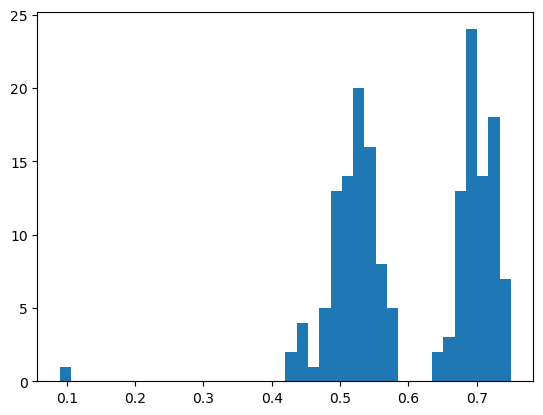

In [39]:
plt.hist(corr, bins = 40);


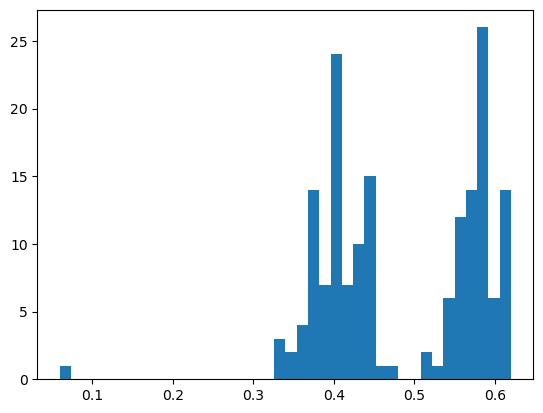

In [33]:
plt.hist(corr, bins = 40);

In [460]:

mat = loadmat(pat + np.sort(os.listdir('/readonly/insights/RESULTS_YA_new_1000/RESULTS_YA_new_1000_RUN1_noisevar/'))[subject])['A']


x = (dediag(js[0]))

y = (dediag(js[1]))
mask = np.abs(y)<1e-2


x = (dediag(js[0]))[np.logical_not(mask)]
y = (dediag(js[1]))[np.logical_not(mask)]

res = linregress(x.flatten(), y.flatten())
slope, intercept, r, p = res.slope, res.intercept, round(res.rvalue,2), res.pvalue


(3532,)

NameError: name 'JS_2' is not defined

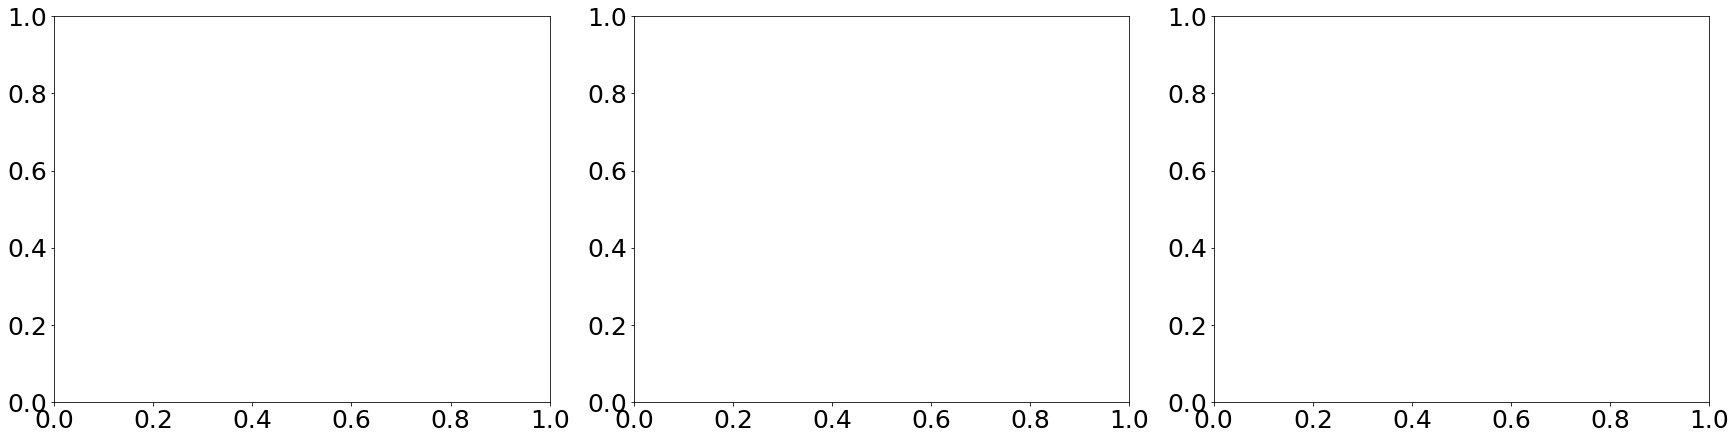

In [23]:
# Crea figura con 1 riga e 3 colonne
fig, axes = plt.subplots(1, 3, figsize=(24,6)  ,constrained_layout=True)
from mpl_toolkits.axes_grid1 import make_axes_locatable
subject = 36

plt.rcParams["axes.titlesize"] = 28
plt.rcParams["axes.labelsize"] = 22
plt.rcParams["xtick.labelsize"] = 22
plt.rcParams["ytick.labelsize"] = 22
ikk=[]
pat = '/readonly/insights/RESULTS_YA_new_1000/RESULTS_YA_new_1000_RUN2'
for i in os.listdir('/readonly/insights/RESULTS_YA_new_1000/RESULTS_YA_new_1000_RUN2'):
    if i[-10:-4] in sub_tot:
        ikk.append(i[-10:-4])
#ikk
#len(ikk)
#ikk[:10]
ikk = np.sort(ikk)
indicia = np.asarray([np.where(ikk[i]==sub_tot)[0] for i in range(len(ikk))]).reshape(-1)
indicia.shape


# Primo pannello
v = [0.2,0.2]
#matt = loadmat(pat + np.sort(os.listdir('/readonly/insights/RESULTS_YA_new_1000/RESULTS_YA_new_1000_R/'))[subject])['A']
js=[JS_2[indicia][subject], matt[subject].T]

#js =[JS[subject][:62,:62], JS_100_1[subject][:100,:100], JS_200_1[subject][:200,:200], JS[subject][:62,:62],cluster_regions_EC(JS_100_1[subject][:100,:100], aggregate[:100]), cluster_regions_EC(mapping_100_200(JS_200_1[subject][:200,:200]), aggregate[:100])]

titles = ['MOU EC', 'Sparse DCM EC',]
for i,ax in enumerate(axes.reshape(-1)[:2]):
    im= ax.imshow(js[i], vmin=-v[i], vmax=v[i], cmap = 'RdBu_r');
    divider = make_axes_locatable(ax)
    cax = divider.append_axes('right', size='5%', pad=0.05)
    fig.colorbar(im, cax=cax, orientation='vertical')
    ax.set_title(f"{titles[i]}",pad=15)
    ax.set_xlabel('ROIs')
    ax.set_ylabel('ROIs')
    


x = (dediag(js[0]))

y = (dediag(js[1]))
mask = np.abs(y)<1e-2


x = (dediag(js[0]))[np.logical_not(mask)]
y = (dediag(js[1]))[np.logical_not(mask)]

res = linregress(x.flatten(), y.flatten())
slope, intercept, r, p = res.slope, res.intercept, round(res.rvalue,2), res.pvalue


im= axes[-1].scatter(x,y,c = 'white',edgecolor ="#4393c3") #(blu molto scuro))
#, vmin=-v[i], vmax=v[i], cmap = 'bwr');


x = dediag(js[0])[(mask)]
y = (dediag(js[1]))[(mask)]



im= axes[-1].scatter(x,y,c = 'white',edgecolor = "#ff8f8a"
              )

y_line = slope * x.flatten() + intercept
axes[-1].plot(x.flatten(), y_line, linewidth=2, color ='darkred')
print(slope, r)
from scipy import stats
#res = stats.spearmanr(x.flatten(), y.flatten())
# Titolo completo
#print('sp', res)
axes[-1].set_title(f"{titles[i]}")
axes[-1].set_xlabel('Sparse DCM EC')
axes[-1].set_ylabel('MOU EC') if i == 0 else axes[-1].set_ylabel('MOU EC') 

# --- Testo dentro la figura ---
text_str = f"r = {r:.2f}"
axes[-1].text(
    0.05, 0.95,              # posizione (fractions dell'asse)
    text_str,
    transform=axes[-1].transAxes,  # usa coordinate normalizzate
    verticalalignment='top',
    fontsize=24,
    bbox=dict(facecolor='white', alpha=0.7, edgecolor='none')
    )


#print(i)
plt.subplots_adjust(wspace=.8);

In [1]:
whos

Interactive namespace is empty.


1
0.0


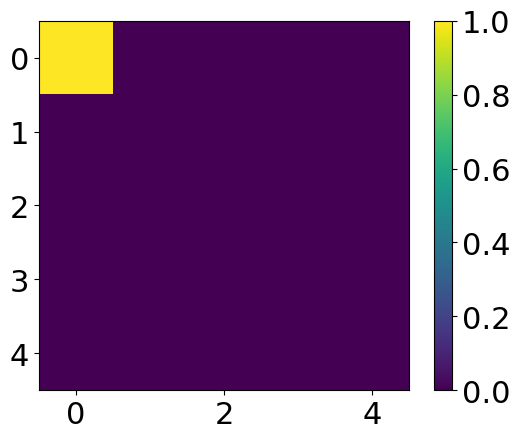

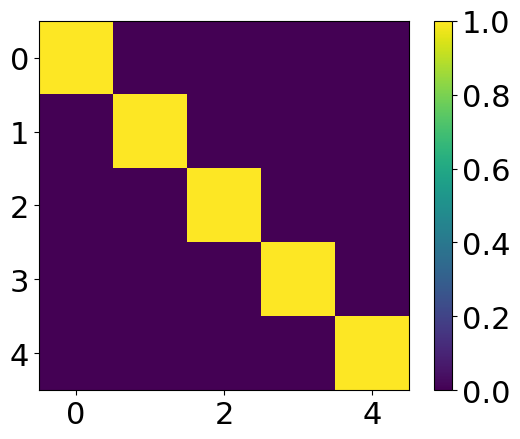

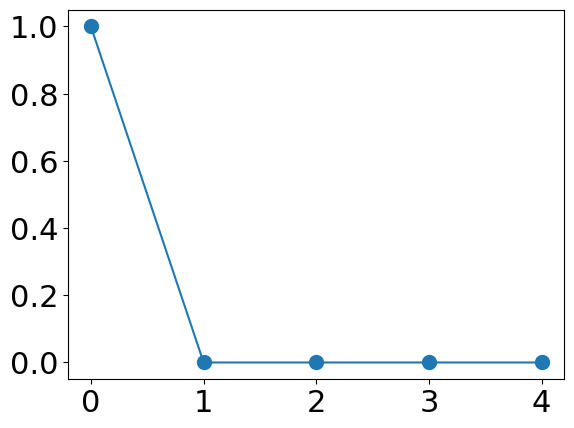

In [259]:
n = np.array([1,0,0,0,0])
m = np.array([1,0,0,0,0])
plt.figure()
plt.imshow(np.outer(n,m))
plt.colorbar()
plt.figure()
print(np.linalg.matrix_rank(np.outer(n,m)))
print(np.linalg.det(np.outer(n,m)))

plt.imshow(np.linalg.eig(np.outer(n,m))[1],);
plt.colorbar()
plt.figure()
plt.plot(np.linalg.eig(np.outer(n,m))[0], '-o', markersize=10);

In [253]:
np.round(np.linalg.eig(np.outer(n,m))[1],2)

array([[ 1., -1.,  0.,  0.,  0.],
       [ 0.,  0.,  0.,  0.,  0.],
       [ 0.,  0.,  1.,  0.,  0.],
       [ 0.,  0.,  0.,  1.,  0.],
       [ 0.,  0.,  0.,  0.,  1.]])

In [60]:
from mou_model import *